# **Projeto 2: alocação estável de alunos em projetos**

Universidade de Brasília, Departamento de Ciência da Computação

Teoria e Aplicação de Grafos, Turma A, 2026/2, Prof. Díbio

| Integrante | Matrícula |
|---|---|
| Gabrielly Batista de Freitas | 251004400 |
| Helena Miranda Longo | 251004302 |

Este notebook contém o código, a descrição textual da variação do algoritmo de Gale-Shapley, as simulações de dez iterações nos dois sentidos (aluno propõe e projeto propõe), a matriz final de emparelhamentos e as verificações de estabilidade e de otimalidade. 

## Mapa do notebook

Cada etapa abaixo produz uma saída verificável. Quando `SALVARSAIDAS = True` (padrão), as figuras vão para `../figuras` e as tabelas para `../resultados`, então rodar o notebook do início ao fim regenera todos os arquivos do projeto.

| Etapa | O que faz | O que grava |
|---|---|---|
| Início | parâmetros, cores das arestas, pastas de saída | |
| 1 e 1b | leitura, limpeza e visão geral da instância | `figuras/visao-geral-instancia.png`, `resultados/ocorrencias-limpeza.csv` |
| 2 | grafo bipartido de entrada e listas de preferência dos projetos | `figuras/grafo-entrada.png` |
| 3 e 3b | índice de preferência por projeto e demanda contra vagas | `figuras/indice-preferencia.png`, `figuras/demanda-vagas.png`, `resultados/indice-preferencia.csv` |
| 4 | motor do algoritmo (fase 1 e fase 2) | |
| 5 | laço de iterações, log e visualização | |
| 6 e 7 | simulação A (aluno propõe) e B (projeto propõe, proposta final) | `figuras/aluno-propoe-iteracao-NN.png`, `figuras/projeto-propoe-iteracao-NN.png` |
| 8, 8b e 8c | verificação de estabilidade, testes automáticos e animação | `figuras/evolucao-tamanho.png`, `figuras/evolucao-aluno-propoe.gif`, `figuras/evolucao-projeto-propoe.gif`, `resultados/comparacao-versoes.csv` |
| 9, 9b e 9c | matriz final, ganho e perda de cada lado, exportação | `figuras/matriz-final.png`, `figuras/alocacao-final.png`, `figuras/ganho-perda.png`, `resultados/matriz-final.csv` |
| 10, 11 e Conclusões | análise do resultado final | |

**Convenções.** `A12` é o aluno 12 e `P3` é o projeto 3. Uma iteração tem duas fases: a fase 1 é uma rodada de propostas (Gale-Shapley com capacidades) e a fase 2 procura caminhos alternados aumentantes. **Cores das arestas:** azul é proposta ativa, verde é emparelhamento temporário e vermelho é rejeição. Nada neste notebook usa números aleatórios, então duas execuções dão exatamente o mesmo resultado (a etapa 8b testa isso).

## README: o que foi feito e qual variação do algoritmo foi usada

### 1. O problema

Uma universidade oferece 50 projetos que somam 80 vagas, e 200 alunos se candidataram. Cada aluno indica até três projetos em ordem de preferência e tem uma nota agregada inteira em {3, 4, 5}. Cada projeto tem um número de vagas e uma nota mínima exigida. Queremos uma alocação estável, isto é, sem nenhum par aluno-projeto que prefira estar junto em vez de ficar com o que recebeu, e com o maior número possível de alunos alocados, porque quanto mais alunos alocados mais projetos conseguem ser realizados.

Esse é o problema de alocação de alunos a projetos (Student-Project Allocation, SPA) estudado por Abraham, Irving e Manlove (2007). O artigo propõe dois algoritmos, um orientado ao aluno (student-oriented), que devolve a alocação estável melhor para os alunos, e um orientado ao professor (lecturer-oriented), que devolve a alocação estável melhor para o lado dos projetos. No arquivo de entrada não há professores com limite próprio de carga, então cada projeto equivale ao único projeto de um orientador cujo limite é o próprio número de vagas. Com isso a camada dos professores não tem efeito e o problema fica igual ao problema de Hospitais e Residentes: alunos são os residentes e projetos são os hospitais, cada um com capacidade. Os dois algoritmos do artigo se reduzem, nesse caso, às duas versões clássicas do Gale-Shapley com capacidades.

### 2. Modelagem em grafos

Montamos um grafo bipartido em que um lado é o conjunto de alunos e o outro é o conjunto de projetos. Existe uma aresta (aluno, projeto) quando o aluno colocou o projeto na sua lista e a nota dele atinge o requisito do projeto. Pares barrados pela nota não viram aresta. Um emparelhamento é um conjunto de arestas em que cada aluno aparece no máximo uma vez e cada projeto aparece no máximo tantas vezes quanto suas vagas (um emparelhamento com capacidades).

A preferência dos alunos é a ordem que eles indicaram. O arquivo não traz preferência dos projetos, então ela é construída a partir da nota: nota maior é melhor. Como só existem três valores de nota, há muitos empates. Para rodar o Gale-Shapley precisamos de uma lista estrita, então os empates são desfeitos de forma determinística, sem sorteio: entre alunos de mesma nota vem primeiro quem colocou o projeto em posição melhor na sua lista, e se ainda assim empatar vem o menor código de aluno. Essa lista estrita é a Lista de Preferência do Projeto que aparece na matriz final. A parametrização `DESEMPATE` permite testar outras regras.

### 3. O que significa estável aqui

Um par (aluno a, projeto p) que não está no emparelhamento é um par bloqueante quando a prefere p ao projeto que recebeu (ou ficou sem nada) e p tem vaga livre ou prefere a a algum aluno que já recebeu. Um emparelhamento sem pares bloqueantes é estável. Usamos duas versões da definição.

Na estabilidade estrita, "p prefere a" significa estar à frente na lista estrita de p, incluindo o desempate. Na estabilidade fraca, p só prefere a quando a nota de a é estritamente maior que a de algum aluno de p. A segunda é a definição fiel aos dados, porque dois alunos com a mesma nota são equivalentes para o projeto e o desempate foi uma escolha nossa para poder rodar o algoritmo. Todo emparelhamento estável no sentido estrito também é estável no sentido fraco, mas não o contrário.

### 4. A variação do algoritmo (descrição pedida no enunciado)

**Pré-processamento.** Lemos o arquivo, descartamos preferências por projetos que não existem, descartamos repetições dentro da mesma lista e retiramos as arestas barradas pela nota mínima. Em seguida construímos a lista de cada projeto, ordenada por nota com o desempate descrito acima.

**Laço de 10 iterações.** Cada iteração tem duas fases, executadas sempre na mesma ordem e sem nenhum sorteio.

*Fase 1, uma rodada de aceitação adiada (Gale-Shapley com capacidades).* Existem duas versões e as duas são simuladas.
- Aluno propõe: cada aluno livre que ainda tem projeto não testado propõe ao próximo projeto da sua lista. Cada projeto junta as propostas novas com os alunos que já segurava, fica com os melhores até o limite de vagas (emparelhamento temporário) e rejeita o resto. Quem é rejeitado volta a ficar livre.
- Projeto propõe: cada projeto com vaga livre propõe aos próximos alunos da sua lista, um por vaga livre. Cada aluno junta as propostas recebidas com o projeto que já segurava, fica com o melhor segundo a sua própria ordem e rejeita os demais. A vaga do projeto rejeitado volta a ficar livre.

Em termos de caminhos alternados, uma proposta é uma aresta fora do emparelhamento e uma rejeição ou substituição é uma aresta do emparelhamento que sai. Quando um aluno livre propõe, desloca alguém, e o deslocado propõe em seguida, estamos percorrendo um caminho alternado que cresce um passo por iteração e que termina quando alguém encontra vaga livre (o emparelhamento aumenta em um) ou quando alguém esgota a lista. Por isso, a cada iteração, o ponto de partida são os alunos que ficaram sem emparelhamento na iteração anterior.

*Fase 2, caminhos alternados aumentantes que passam por empates.* Quando a fase 1 não tem mais propostas a fazer, o emparelhamento é estável no sentido estrito, mas ainda pode haver alunos livres que cabem se alguém de nota igual se mover para outro projeto. A fase 2 procura, a partir dos alunos livres, caminhos alternados que terminam em um projeto com vaga livre. A busca é em profundidade com aprofundamento iterativo, então o caminho mais curto é testado primeiro, e os alunos são percorridos em ordem de código, o que a torna determinística. Cada caminho candidato é aplicado em uma cópia do emparelhamento e só é aceito se a cópia respeitar as vagas e não tiver nenhum par bloqueante no sentido fraco. Assim o emparelhamento cresce sem perder a estabilidade. Cada iteração aceita no máximo um caminho, para que a evolução possa ser acompanhada passo a passo.

**Critério de parada.** O laço roda as 10 iterações pedidas. Ele fica estacionário quando uma iteração não tem propostas na fase 1 e nenhum caminho aumentante estável na fase 2. O programa avisa se isso não tiver acontecido até a décima iteração.

**Projetos sem alunos.** Todo projeto realizado precisa de pelo menos um aluno. Um projeto que termina com zero alunos é marcado como não realizado e o programa explica o motivo (sem candidato qualificado, ou candidatos que preferiram outros projetos).

**Resposta final.** Como pede o enunciado, a proposta final é a do lado do projeto (a lista de preferência do projeto conduz as propostas), seguida da fase 2. A versão em que o aluno propõe também é simulada e mostrada, e as duas são comparadas.

**Custo.** Na fase 1 cada aresta é proposta no máximo uma vez, então o custo total é linear no número de arestas. A fase 2 é uma busca com limite de comprimento (`MAXPASSOSCAMINHO`), porque encontrar o maior emparelhamento estável quando há empates é um problema difícil em geral.

### 5. Inconsistências no arquivo de entrada e o que fizemos

- Cinco alunos citam projetos que não existem: A2 (P51), A39 (P53), A51 (P52), A95 (P53) e A108 (P54). Essas preferências são ignoradas.
- Onze alunos repetem um projeto na própria lista (A63, A64, A67, A89, A118, A119, A133, A141, A163, A164 e A167). Vale a primeira ocorrência e a repetição é ignorada, então esses alunos ficam com menos de três opções.
- A linha de A177 não tem espaço entre ")" e "(5)". A leitura por expressão regular tolera isso.
- Trezentos pares aluno-projeto são barrados porque a nota do aluno é menor que o requisito do projeto. Eles não entram no grafo, mas aparecem na figura do grafo de entrada.
- A ordem de escolha mostrada na matriz final é a posição do projeto na lista original do aluno. Se o primeiro projeto de um aluno não existe, o segundo continua sendo contado como segunda escolha.

### 6. Como executar

No Jupyter, abra o notebook dentro da pasta `notebook` do projeto e use Run All: a entrada é lida de `../data/entradaProj2.26TAG.txt`. Se o arquivo estiver na pasta do notebook, ele também é encontrado. No Google Colab, execute a primeira célula de código e escolha o arquivo quando o botão de envio aparecer. Os parâmetros ficam na primeira célula de código: número de iterações, regra de desempate, limite do caminho aumentante e se os gráficos devem ser desenhados. Para gravar ou não as figuras e as tabelas existe `SALVARSAIDAS`.

### 7. O que o notebook grava e como conferir fora dele

Com `SALVARSAIDAS = True`, cada figura vira um PNG em `figuras/` e cada tabela vira um CSV em `resultados/` (a lista completa está no mapa no início do notebook). A alocação final fica em `resultados/matriz-final.csv`. O script `verificacao/verifica.py` relê a entrada e esse CSV com código próprio, confere vagas, listas elegíveis, classificações e pares bloqueantes, e compara o tamanho obtido com o ótimo calculado por programação linear inteira. No Colab os arquivos ficam no disco temporário da sessão, e a última célula da etapa 9 oferece o download de um zip com tudo.


## **Início.** Configuração

Importamos as bibliotecas, definimos os parâmetros e as cores das arestas. As três cores pedidas no enunciado são azul para proposta ativa, verde para emparelhamento temporário e vermelho para rejeição. No Colab, se o arquivo de entrada não estiver na pasta de trabalho, a célula abre o seletor de arquivos. A célula também define as pastas de saída e duas funções de apoio, `salvarfigura` e `salvartabela`, usadas ao longo do notebook, e imprime as versões das bibliotecas para que o resultado possa ser reproduzido.

In [23]:
import os, io, re, math, time, platform
from collections import defaultdict, Counter
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from PIL import Image
from matplotlib.lines import Line2D
from matplotlib.collections import LineCollection
from matplotlib.colors import ListedColormap, BoundaryNorm
from IPython.display import display

# parâmetros do experimento
ARQUIVO = '../data/entradaProj2.26TAG.txt'   # estrutura do projeto: notebook/ e data/ lado a lado
NITERACOES = 10            # número de iterações do laço, fixado pelo enunciado
DESEMPATE = 'escolha'       # 'escolha', 'escassez' ou 'codigo' (ver etapa 2)
MAXPASSOSCAMINHO = 12     # número máximo de alunos em um caminho aumentante
MOSTRARGRAFICOS = True     # False acelera a execução se só os textos interessarem
LIMITELISTA = 40           # acima disso o log mostra só contagens e não cada proposta
SALVARSAIDAS = True        # grava as figuras (PNG) e as tabelas (CSV) nas pastas definidas abaixo
DPISALVAR = 100            # resolução dos PNGs gravados (a exibição no notebook usa dpi menor)
GERARANIMACAO = True       # monta um GIF com a evolução das 10 iterações (etapa 8c)

# cores das arestas
CORPROPOSTA = '#1f77b4'    # azul: proposta ativa
CORTEMPORARIO = '#2ca02c'  # verde: emparelhamento temporário
CORREJEICAO = '#d62728'    # vermelho: rejeição
CORFUNDO = '#c8c8c8'       # cinza: aresta elegível ainda sem evento
CORBARRADA = '#ff9f1c'     # laranja: barrada pela nota mínima (só no grafo de entrada)

plt.rcParams['figure.dpi'] = 60
pd.set_option('display.max_rows', 300)
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 200)
pd.set_option('display.max_colwidth', 90)

# localiza o arquivo de entrada: primeiro em ../data, depois na pasta do notebook
if not os.path.exists(ARQUIVO) and os.path.exists('entradaProj2.26TAG.txt'):
    ARQUIVO = 'entradaProj2.26TAG.txt'
if not os.path.exists(ARQUIVO):
    try:
        from google.colab import files
        print('Selecione o arquivo entradaProj2.26TAG.txt')
        enviados = files.upload()
        ARQUIVO = list(enviados.keys())[0]
    except ImportError:
        raise FileNotFoundError(f'Arquivo {ARQUIVO} não encontrado na pasta do notebook.')
print('Arquivo de entrada:', ARQUIVO)

# pastas de saída: ao lado de ../data quando o notebook está dentro do projeto,
# ou na pasta de trabalho quando a entrada foi enviada (por exemplo no Colab)
RAIZ = '..' if os.path.abspath(ARQUIVO).replace('\\', '/').endswith('/data/' + os.path.basename(ARQUIVO)) else '.'
PASTAFIGURAS = os.path.join(RAIZ, 'figuras')
PASTARESULTADOS = os.path.join(RAIZ, 'resultados')


def salvarfigura(fig, nome):
    """Grava a figura em PASTAFIGURAS/nome.png quando SALVARSAIDAS é True.
    Deve ser chamada antes de plt.show(), que fecha a figura. O PNG usa paleta de
    256 cores, sem diferença visível nestes gráficos e com cerca de um terço do tamanho."""
    if not SALVARSAIDAS:
        return None
    os.makedirs(PASTAFIGURAS, exist_ok=True)
    caminho = os.path.join(PASTAFIGURAS, nome + '.png')
    buf = io.BytesIO()
    fig.savefig(buf, format='png', dpi=DPISALVAR, bbox_inches='tight', facecolor='white')
    buf.seek(0)
    Image.open(buf).convert('RGB').quantize(colors=256, method=Image.Quantize.MEDIANCUT,
                                            dither=Image.Dither.NONE).save(caminho, optimize=True)
    return caminho


def salvartabela(df, nome, indice=False):
    """Grava a tabela em PASTARESULTADOS/nome.csv (UTF-8 com BOM, abre certo no Excel)."""
    if not SALVARSAIDAS:
        return None
    os.makedirs(PASTARESULTADOS, exist_ok=True)
    caminho = os.path.join(PASTARESULTADOS, nome + '.csv')
    df.to_csv(caminho, index=indice, encoding='utf-8-sig')
    return caminho


print(f'Python {platform.python_version()} | numpy {np.__version__} | pandas {pd.__version__} | matplotlib {matplotlib.__version__}')
print('Saídas em:', os.path.abspath(RAIZ) + ' (figuras/ e resultados/)' if SALVARSAIDAS else '(desligado: SALVARSAIDAS = False)')


Arquivo de entrada: ../data/entradaProj2.26TAG.txt
Python 3.14.2 | numpy 2.5.4 | pandas 3.0.6 | matplotlib 3.11.2
Saídas em: C:\Users\hmlon\OneDrive\Desktop\TAG-2026-2-proj2\TAG-2026-2-proj2 (figuras/ e resultados/)


## **Etapa 1.** Leitura e limpeza dos dados

O arquivo tem duas seções. A primeira lista os projetos no formato (código, vagas, nota mínima) e a segunda lista os alunos no formato (código):(preferências) (nota). Usamos expressões regulares para ler, o que tolera espaços irregulares como o da linha de A177.

Depois da leitura, cada lista de preferências passa por três filtros, nesta ordem: projeto inexistente, projeto repetido na lista e nota abaixo do requisito. Tudo que for descartado é registrado em uma tabela de ocorrências, para que nada seja removido sem aparecer. Para cada aluno guardamos também a posição original de cada projeto elegível, porque a matriz final mostra a ordem de escolha como o aluno a escreveu.

In [24]:
def lerentrada(caminho):
    """Lê o arquivo e devolve dois dicionários: projetos e alunos."""
    texto = open(caminho, encoding='utf-8').read()
    projetos, alunos = {}, {}
    # (P12, 2, 5): código, vagas, nota mínima
    for m in re.finditer(r'\(P(\d+)\s*,\s*(\d+)\s*,\s*(\d+)\)', texto):
        projetos[int(m[1])] = {'vagas': int(m[2]), 'req': int(m[3])}
    # (A7):(P41, P31, P38) (4): código, preferências em ordem, nota
    for m in re.finditer(r'\(A(\d+)\)\s*:\s*\(([^)]*)\)\s*\((\d+)\)', texto):
        prefs = [int(x.strip().lstrip('Pp')) for x in m[2].split(',') if x.strip()]
        alunos[int(m[1])] = {'prefsoriginais': prefs, 'nota': int(m[3])}
    return projetos, alunos


def limparpreferencias(projetos, alunos):
    """Aplica os filtros de limpeza e devolve a tabela de ocorrências."""
    ocorrencias = []
    for a in sorted(alunos):
        d = alunos[a]
        vistos, elegiveis, escolha, validastodas, barradas = set(), [], {}, [], []
        for pos, p in enumerate(d['prefsoriginais'], start=1):
            if p not in projetos:
                ocorrencias.append((f'A{a}', 'projeto inexistente', f'P{p}'))
                continue
            if p in vistos:
                ocorrencias.append((f'A{a}', 'projeto repetido na lista', f'P{p}'))
                continue
            vistos.add(p)
            validastodas.append(p)
            if d['nota'] < projetos[p]['req']:
                ocorrencias.append((f'A{a}', 'nota abaixo do requisito',
                                    f"P{p} (nota {d['nota']}, exige {projetos[p]['req']})"))
                barradas.append(p)
                continue
            elegiveis.append(p)
            escolha[p] = pos          # posição na lista original do aluno
        d['prefs'] = elegiveis        # projetos elegíveis, na ordem do aluno
        d['escolha'] = escolha
        d['validastodas'] = validastodas
        d['barradas'] = barradas
    return pd.DataFrame(ocorrencias, columns=['Aluno', 'Ocorrência', 'Detalhe'])


projetos, alunos = lerentrada(ARQUIVO)
dfocorrencias = limparpreferencias(projetos, alunos)

print(f'Projetos lidos: {len(projetos)}   Alunos lidos: {len(alunos)}')
print(f"Total de vagas: {sum(d['vagas'] for d in projetos.values())}")
print('Distribuição das notas dos alunos:', dict(sorted(Counter(d['nota'] for d in alunos.values()).items())))
print('Distribuição dos requisitos dos projetos:', dict(sorted(Counter(d['req'] for d in projetos.values()).items())))
print()
print('Ocorrências encontradas na limpeza:')
print(dfocorrencias['Ocorrência'].value_counts().to_string())
print()
display(dfocorrencias[dfocorrencias['Ocorrência'] != 'nota abaixo do requisito'])
nsemopcao = sum(1 for d in alunos.values() if not d['prefs'])
print(f'Alunos sem nenhuma opção elegível (todas barradas ou inexistentes): {nsemopcao}')
print(f"Alunos com pelo menos uma opção elegível: {len(alunos) - nsemopcao}")

Projetos lidos: 50   Alunos lidos: 200
Total de vagas: 80
Distribuição das notas dos alunos: {3: 69, 4: 98, 5: 33}
Distribuição dos requisitos dos projetos: {3: 3, 4: 26, 5: 21}

Ocorrências encontradas na limpeza:
Ocorrência
nota abaixo do requisito     300
projeto repetido na lista     11
projeto inexistente            5



,Aluno,Ocorrência,Detalhe
0,A2,projeto inexistente,P51
61,A39,projeto inexistente,P53
76,A51,projeto inexistente,P52
91,A63,projeto repetido na lista,P39
92,A64,projeto repetido na lista,P30
97,A67,projeto repetido na lista,P31
138,A89,projeto repetido na lista,P19
146,A95,projeto inexistente,P53
165,A108,projeto inexistente,P54
186,A118,projeto repetido na lista,P28


Alunos sem nenhuma opção elegível (todas barradas ou inexistentes): 66
Alunos com pelo menos uma opção elegível: 134


### **Etapa 1b.** Visão geral da instância

Antes de rodar o algoritmo resumimos o tamanho do problema e como as notas e as listas se distribuem. A tabela conta o que entrou e o que foi descartado na limpeza. A figura tem três painéis: quantos alunos têm cada nota contra quantos projetos exigem cada nota, quantos alunos ficaram com 0, 1, 2 ou 3 opções elegíveis depois dos filtros, e quantos projetos oferecem 1 ou 2 vagas. O segundo painel é importante porque um aluno sem nenhuma opção elegível não tem como ser alocado, por mais que o algoritmo tente.

Medida,Valor
Projetos,50
Vagas totais,80
Alunos que se candidataram,200
Alunos com pelo menos uma opção elegível,134
Alunos sem nenhuma opção elegível,66
Arestas elegíveis no grafo bipartido,280
Pares aluno-projeto barrados pela nota mínima,300
Preferências ignoradas (projeto inexistente ou repetido),16


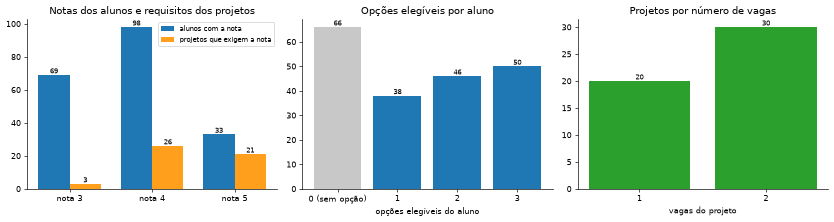

In [25]:
ignoradas = int((dfocorrencias['Ocorrência'] != 'nota abaixo do requisito').sum())
barradas = int((dfocorrencias['Ocorrência'] == 'nota abaixo do requisito').sum())
nopcoes = Counter(len(d['prefs']) for d in alunos.values())
resumo = pd.DataFrame({
    'Medida': ['Projetos', 'Vagas totais', 'Alunos que se candidataram',
               'Alunos com pelo menos uma opção elegível', 'Alunos sem nenhuma opção elegível',
               'Arestas elegíveis no grafo bipartido', 'Pares aluno-projeto barrados pela nota mínima',
               'Preferências ignoradas (projeto inexistente ou repetido)'],
    'Valor': [len(projetos), sum(d['vagas'] for d in projetos.values()), len(alunos),
              len(alunos) - nopcoes[0], nopcoes[0], sum(len(d['prefs']) for d in alunos.values()),
              barradas, ignoradas]})
display(resumo.style.hide(axis='index'))

if MOSTRARGRAFICOS:
    fig, axs = plt.subplots(1, 3, figsize=(14, 3.8))
    notas = [3, 4, 5]
    larg = 0.38
    xs = np.arange(len(notas))
    contalunos = Counter(d['nota'] for d in alunos.values())
    contreq = Counter(d['req'] for d in projetos.values())
    axs[0].bar(xs - larg / 2, [contalunos[n] for n in notas], larg, color=CORPROPOSTA, label='alunos com a nota')
    axs[0].bar(xs + larg / 2, [contreq[n] for n in notas], larg, color=CORBARRADA, label='projetos que exigem a nota')
    axs[0].set_xticks(xs)
    axs[0].set_xticklabels([f'nota {n}' for n in notas])
    axs[0].set_title('Notas dos alunos e requisitos dos projetos')
    axs[0].legend(fontsize=8)
    cores2 = [CORFUNDO, CORPROPOSTA, CORPROPOSTA, CORPROPOSTA]
    axs[1].bar(range(4), [nopcoes[k] for k in range(4)], color=cores2)
    axs[1].set_xticks(range(4))
    axs[1].set_xticklabels(['0 (sem opção)', '1', '2', '3'])
    axs[1].set_xlabel('opções elegíveis do aluno')
    axs[1].set_title('Opções elegíveis por aluno')
    vg = Counter(d['vagas'] for d in projetos.values())
    axs[2].bar([str(v) for v in sorted(vg)], [vg[v] for v in sorted(vg)], color=CORTEMPORARIO)
    axs[2].set_xlabel('vagas do projeto')
    axs[2].set_title('Projetos por número de vagas')
    for ax in axs:
        for r in ax.patches:
            ax.text(r.get_x() + r.get_width() / 2, r.get_height(), int(r.get_height()), ha='center', va='bottom', fontsize=8)
        ax.spines[['top', 'right']].set_visible(False)
    plt.tight_layout()
    salvarfigura(fig, 'visao-geral-instancia')
    plt.show()

## **Etapa 2.** Grafo bipartido e listas de preferência dos projetos

A classe `Instancia` reúne tudo que o algoritmo consulta: vagas, notas, listas elegíveis dos alunos e a lista de preferência de cada projeto, já ordenada. Para cada projeto, os candidatos são os alunos com aresta nele, e a lista é ordenada por nota decrescente com desempate determinístico. Há três regras de desempate disponíveis:

- `escolha` (padrão): entre alunos de mesma nota vem primeiro quem colocou o projeto em posição melhor, depois o menor código. Premia o interesse declarado.
- `escassez`: entre alunos de mesma nota vem primeiro quem tem menos opções elegíveis, depois a posição de escolha, depois o código. Favorece quem tem menos alternativas.
- `codigo`: desempata só pelo código do aluno.

`pos[p][a]` guarda a posição do aluno a na lista do projeto p (1 é o melhor). Esse número é o "Top k de n alunos na lista" da matriz final.

A figura em seguida mostra o grafo bipartido de entrada. As arestas cinzas são as elegíveis e as laranjas tracejadas são as barradas pela nota mínima. Alunos sem nenhuma aresta elegível aparecem em cinza claro.

In [26]:
class Instancia:
    """Dados do problema depois da limpeza, prontos para o algoritmo."""
    def __init__(self, projetos, alunos, desempate='escolha'):
        self.projetos, self.alunos = projetos, alunos
        self.vagas = {p: d['vagas'] for p, d in projetos.items()}
        self.req = {p: d['req'] for p, d in projetos.items()}
        self.nota = {a: d['nota'] for a, d in alunos.items()}
        self.prefs = {a: d['prefs'] for a, d in alunos.items()}
        self.escolha = {a: d['escolha'] for a, d in alunos.items()}
        self.elegiveis = [a for a in sorted(alunos) if alunos[a]['prefs']]
        # candidatos de cada projeto: alunos com aresta elegível
        self.cand = {p: [] for p in projetos}
        for a in sorted(alunos):
            for p in self.prefs[a]:
                self.cand[p].append(a)
        chaves = {
            'escolha':  lambda a, p: (-self.nota[a], self.escolha[a][p], a),
            'escassez': lambda a, p: (-self.nota[a], len(self.prefs[a]), self.escolha[a][p], a),
            'codigo':   lambda a, p: (-self.nota[a], a),
        }
        chave = chaves[desempate]
        # lista de preferência estrita de cada projeto
        self.lista = {p: sorted(self.cand[p], key=lambda a, p=p: chave(a, p)) for p in projetos}
        self.pos = {p: {a: i for i, a in enumerate(self.lista[p], start=1)} for p in projetos}


I = Instancia(projetos, alunos, DESEMPATE)
narestas = sum(len(v) for v in I.prefs.values())
print(f'Regra de desempate: {DESEMPATE}')
print(f'Arestas elegíveis no grafo bipartido: {narestas}')
for p in (20, 30, 28):
    topo = ', '.join(f'A{a}(nota {I.nota[a]})' for a in I.lista[p][:6])
    print(f'Lista de P{p} ({I.vagas[p]} vagas, exige {I.req[p]}, {len(I.lista[p])} candidatos), primeiros 6: {topo}')

Regra de desempate: escolha
Arestas elegíveis no grafo bipartido: 280
Lista de P20 (1 vagas, exige 4, 15 candidatos), primeiros 6: A32(nota 5), A64(nota 5), A100(nota 5), A200(nota 5), A24(nota 4), A41(nota 4)
Lista de P30 (1 vagas, exige 4, 16 candidatos), primeiros 6: A64(nota 5), A1(nota 5), A2(nota 5), A33(nota 5), A83(nota 5), A66(nota 4)
Lista de P28 (1 vagas, exige 3, 14 candidatos), primeiros 6: A127(nota 5), A18(nota 5), A137(nota 5), A48(nota 4), A58(nota 4), A148(nota 4)


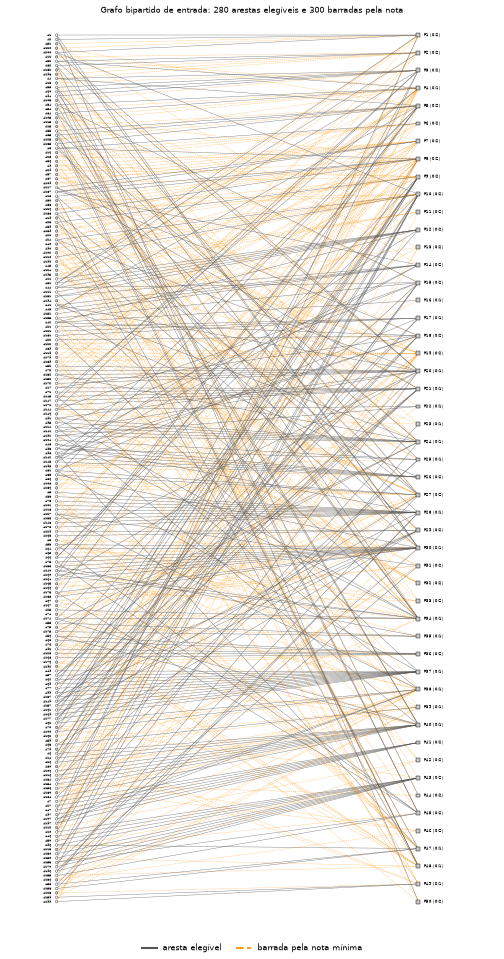

In [27]:
# funções de desenho (usadas aqui e nas simulações)
def layoutbipartido(I, alunosexibidos):
    """Alunos na coluna x=0 e projetos na coluna x=1. A ordem dos alunos segue o
    primeiro projeto da lista, o que reduz o cruzamento de arestas."""
    def chave(a):
        base = I.prefs[a] or I.alunos[a]['validastodas']
        return (base[0] if base else 999, a)
    ordem = sorted(alunosexibidos, key=chave)
    ys = {a: 1 - i / max(len(ordem) - 1, 1) for i, a in enumerate(ordem)}
    ps = sorted(I.projetos)
    yp = {p: 1 - i / (len(ps) - 1) for i, p in enumerate(ps)}
    return ys, yp


def desenharpainel(ax, I, ys, yp, par, camadas, titulo, rotulos=True):
    """Desenha um painel do grafo bipartido. 'camadas' é uma lista de
    (arestas, cor, espessura, transparência, estilo) desenhadas nessa ordem."""
    for arestas, cor, lw, alpha, estilo in camadas:
        segs = [[(0, ys[a]), (1, yp[p])] for a, p in arestas if a in ys]
        if segs:
            ax.add_collection(LineCollection(segs, colors=cor, linewidths=lw, alpha=alpha, linestyles=estilo))
    ocup = Counter(par.values())
    # alunos: verde = emparelhado, branco = livre com opções, cinza = sem opção elegível
    coresa = [CORTEMPORARIO if a in par else ('white' if I.prefs[a] else CORFUNDO) for a in ys]
    ax.scatter([0] * len(ys), list(ys.values()), s=9, c=coresa, edgecolors='black', linewidths=0.4, zorder=3)
    # projetos: verde = tem pelo menos um aluno, cinza = vazio
    coresp = [CORTEMPORARIO if ocup[p] > 0 else CORFUNDO for p in yp]
    ax.scatter([1] * len(yp), list(yp.values()), s=22, c=coresp, marker='s', edgecolors='black', linewidths=0.5, zorder=3)
    if rotulos:
        for a, y in ys.items():
            ax.text(-0.015, y, f'A{a}', ha='right', va='center', fontsize=4)
        for p, y in yp.items():
            ax.text(1.015, y, f'P{p} ({ocup[p]}/{I.vagas[p]})', ha='left', va='center', fontsize=5)
    ax.set_xlim(-0.14, 1.22)
    ax.set_ylim(-0.02, 1.02)
    ax.set_title(titulo, fontsize=10)
    ax.axis('off')


def legenda(fig, itens, ncol):
    fig.legend(handles=[Line2D([0], [0], color=c, lw=2.5, ls=ls, label=r) for r, c, ls in itens],
               loc='lower center', ncol=ncol, fontsize=9, frameon=False)


def desenharentrada(I):
    """Grafo bipartido de entrada: arestas elegíveis e arestas barradas pela nota."""
    todos = sorted(I.alunos)
    ys, yp = layoutbipartido(I, todos)
    elegiveis = [(a, p) for a in todos for p in I.prefs[a]]
    barradas = [(a, p) for a in todos for p in I.alunos[a]['barradas']]
    fig, ax = plt.subplots(figsize=(8.5, 16))
    desenharpainel(ax, I, ys, yp, {}, [(barradas, CORBARRADA, 0.5, 0.7, 'dashed'),
                                        (elegiveis, '#555555', 0.5, 0.8, 'solid')],
                    f'Grafo bipartido de entrada: {len(elegiveis)} arestas elegíveis e {len(barradas)} barradas pela nota')
    legenda(fig, [('aresta elegível', '#555555', '-'), ('barrada pela nota mínima', CORBARRADA, '--')], 2)
    plt.tight_layout(rect=(0, 0.03, 1, 1))
    salvarfigura(fig, 'grafo-entrada')
    plt.show()


if MOSTRARGRAFICOS:
    desenharentrada(I)

## **Etapa 3.** Índice de preferência por projeto

O índice mede o quanto cada projeto é desejado pelos alunos que poderiam ocupá-lo. Para cada projeto contamos quantos candidatos qualificados o colocaram em primeira, segunda e terceira escolha (n1, n2 e n3) e calculamos

índice = (3·n1 + 2·n2 + 1·n3) / vagas

Quanto maior o índice, mais concorrido é o projeto em relação às vagas que oferece. Um índice abaixo de 1 indica que mesmo que todos os interessados fossem colocados haveria folga de vagas, e um projeto com índice zero não tem candidato qualificado e não poderá ser realizado. A tabela também mostra os interessados totais (incluindo os barrados pela nota), para separar falta de interesse de falta de qualificação.

,Projeto,Vagas,Nota mín.,Interessados,Barrados pela nota,Qualificados,1ª,2ª,3ª,Índice de preferência
0,P37,1,3,14,0,14,12,0,2,38.00
1,P30,1,4,24,8,16,6,9,1,37.00
2,P40,1,4,22,8,14,3,8,3,28.00
3,P20,1,4,18,3,15,0,12,3,27.00
4,P21,1,4,13,3,10,2,8,0,22.00
5,P24,1,4,18,7,11,4,0,7,19.00
6,P28,1,3,14,0,14,2,1,11,19.00
7,P34,1,4,23,13,10,1,4,5,16.00
8,P17,1,3,6,0,6,0,6,0,12.00
9,P43,2,4,12,3,9,4,5,0,11.00


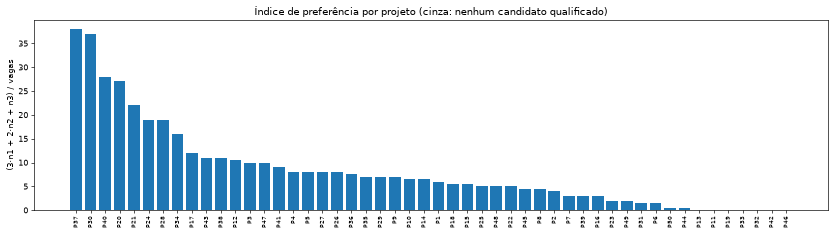

In [28]:
def indicepreferencia(I):
    linhas = []
    for p in sorted(I.projetos):
        n = [0, 0, 0]
        for a in I.cand[p]:
            n[I.escolha[a][p] - 1] += 1
        interessados = sum(1 for a in I.alunos if p in I.alunos[a]['validastodas'])
        indice = (3 * n[0] + 2 * n[1] + 1 * n[2]) / I.vagas[p]
        linhas.append({'Projeto': f'P{p}', 'Vagas': I.vagas[p], 'Nota mín.': I.req[p],
                       'Interessados': interessados, 'Barrados pela nota': interessados - len(I.cand[p]),
                       'Qualificados': len(I.cand[p]), '1ª': n[0], '2ª': n[1], '3ª': n[2],
                       'Índice de preferência': round(indice, 2)})
    return pd.DataFrame(linhas)


dfindice = indicepreferencia(I)
tabindice = dfindice.sort_values('Índice de preferência', ascending=False).reset_index(drop=True)
display(tabindice.style.bar(subset=['Índice de preferência'], color='#9ecae1')
        .background_gradient(subset=['Qualificados'], cmap='Blues')
        .format({'Índice de preferência': '{:.2f}'}))

if MOSTRARGRAFICOS:
    ordenado = dfindice.sort_values('Índice de preferência', ascending=False)
    cores = [CORPROPOSTA if v > 0 else CORFUNDO for v in ordenado['Índice de preferência']]
    fig, ax = plt.subplots(figsize=(14, 4))
    ax.bar(ordenado['Projeto'], ordenado['Índice de preferência'], color=cores)
    ax.set_title('Índice de preferência por projeto (cinza: nenhum candidato qualificado)')
    ax.set_ylabel('(3·n1 + 2·n2 + n3) / vagas')
    plt.xticks(rotation=90, fontsize=7)
    plt.tight_layout()
    salvarfigura(fig, 'indice-preferencia')
    plt.show()

### **Etapa 3b.** Demanda qualificada contra vagas

O índice resume o interesse em um número só. Esta figura mostra a composição: para cada projeto, a barra empilhada conta os candidatos qualificados que o colocaram em primeira, segunda e terceira escolha, e o traço preto marca o número de vagas. Barra acima do traço é projeto disputado, com mais candidatos qualificados do que vagas. Projeto sem barra não tem nenhum candidato qualificado.

Projetos com mais candidatos qualificados do que vagas: 35 de 50


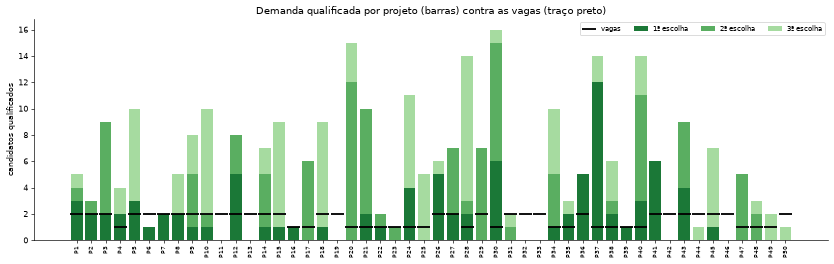

In [29]:
def desenhardemanda(df):
    d = df.assign(num=df['Projeto'].str[1:].astype(int)).sort_values('num')
    x = np.arange(len(d))
    fig, ax = plt.subplots(figsize=(14, 4.5))
    base = np.zeros(len(d))
    for coluna, cor, rotulo in (('1ª', '#1b7837', '1ª escolha'), ('2ª', '#5aae61', '2ª escolha'),
                                ('3ª', '#a6dba0', '3ª escolha')):
        ax.bar(x, d[coluna], bottom=base, color=cor, label=rotulo)
        base += d[coluna].to_numpy()
    ax.hlines(d['Vagas'], x - 0.45, x + 0.45, colors='black', linewidth=2.2, label='vagas')
    ax.set_xticks(x)
    ax.set_xticklabels(d['Projeto'], rotation=90, fontsize=7)
    ax.set_ylabel('candidatos qualificados')
    ax.set_title('Demanda qualificada por projeto (barras) contra as vagas (traço preto)')
    ax.legend(ncol=4, fontsize=8, loc='upper right')
    ax.spines[['top', 'right']].set_visible(False)
    plt.tight_layout()
    salvarfigura(fig, 'demanda-vagas')
    plt.show()


concorridos = int((dfindice['Qualificados'] > dfindice['Vagas']).sum())
print(f'Projetos com mais candidatos qualificados do que vagas: {concorridos} de {len(dfindice)}')
if MOSTRARGRAFICOS:
    desenhardemanda(dfindice)

## **Etapa 4.** O motor do algoritmo

Aqui estão as peças da variação descrita no README.

`paresbloqueantes` testa a estabilidade, estrita ou fraca. `rodadaalunopropoe` e `rodadaprojetopropoe` executam a fase 1, uma rodada síncrona de aceitação adiada em cada sentido. Todas as decisões de uma rodada são tomadas sobre o estado do início da rodada, o que torna o resultado independente de qualquer ordem de execução. `tentaraumentar` executa a fase 2, a busca de caminho alternado aumentante que preserva a estabilidade fraca.

Um caminho aumentante começa em um aluno livre s0, que entra em um projeto p1 cheio, deslocando um aluno s1, que passa para um projeto p2, e assim por diante, até que o último aluno da cadeia entra em um projeto com vaga livre. Os alunos da cadeia trocam de projeto e um aluno livre passa a estar emparelhado, então o tamanho do emparelhamento sobe em um. A busca usa aprofundamento iterativo, tentando primeiro caminhos com um aluno, depois com dois, e assim até `MAXPASSOSCAMINHO`. Por isso o primeiro caminho aceito é sempre um dos mais curtos.

In [30]:
def ocupantes(par):
    """Inverte o emparelhamento: projeto -> lista de alunos."""
    ocup = defaultdict(list)
    for a, p in par.items():
        ocup[p].append(a)
    return ocup


def paresbloqueantes(I, par, fraca=False):
    """Lista os pares (aluno, projeto) que bloqueiam o emparelhamento 'par'.
    fraca=False: o projeto prefere o aluno se ele está à frente na lista estrita.
    fraca=True: o projeto só prefere o aluno se a nota dele é estritamente maior
    que a de algum aluno já alocado (empate de nota não bloqueia)."""
    ocup = ocupantes(par)
    bloq = []
    for a in sorted(I.alunos):
        atual = I.escolha[a][par[a]] if a in par else math.inf
        for p in I.prefs[a]:
            if I.escolha[a][p] >= atual:      # o aluno não prefere p ao que tem
                continue
            if len(ocup[p]) < I.vagas[p]:     # vaga livre: bloqueia
                bloq.append((a, p))
                continue
            if fraca:
                if I.nota[a] > min(I.nota[x] for x in ocup[p]):
                    bloq.append((a, p))
            else:
                pior = max(ocup[p], key=lambda x: I.pos[p][x])
                if I.pos[p][a] < I.pos[p][pior]:
                    bloq.append((a, p))
    return bloq


def rodadaalunopropoe(I, par, prox):
    """Fase 1, versão em que o aluno propõe. 'prox[a]' é o índice da próxima
    proposta do aluno a. Devolve as propostas e as rejeições da rodada."""
    livres = [a for a in I.elegiveis if a not in par and prox[a] < len(I.prefs[a])]
    propostas, porprojeto = [], defaultdict(list)
    for a in livres:                           # ordem de código: determinístico
        p = I.prefs[a][prox[a]]
        prox[a] += 1
        propostas.append((a, p))
        porprojeto[p].append(a)
    rejeicoes = []
    for p in sorted(porprojeto):
        seguros = [a for a, q in par.items() if q == p]
        todos = sorted(seguros + porprojeto[p], key=lambda a: I.pos[p][a])
        for a in todos[I.vagas[p]:]:           # excedem as vagas: rejeitados
            rejeicoes.append((a, p))
            par.pop(a, None)
        for a in todos[:I.vagas[p]]:           # melhores: emparelhamento temporário
            par[a] = p
    return propostas, rejeicoes


def rodadaprojetopropoe(I, par, prox):
    """Fase 1, versão em que o projeto propõe. 'prox[p]' é o índice do próximo
    aluno da lista do projeto p que ainda não recebeu proposta dele."""
    ocup = Counter(par.values())
    propostas, poraluno = [], defaultdict(list)
    for p in sorted(I.projetos):
        livres = I.vagas[p] - ocup[p]
        while livres > 0 and prox[p] < len(I.lista[p]):
            a = I.lista[p][prox[p]]
            prox[p] += 1
            livres -= 1
            propostas.append((a, p))
            poraluno[a].append(p)
    rejeicoes = []
    for a in sorted(poraluno):
        opcoes = poraluno[a] + ([par[a]] if a in par else [])
        melhor = min(opcoes, key=lambda p: I.escolha[a][p])   # a ordem do aluno decide
        for p in opcoes:
            if p != melhor:
                rejeicoes.append((a, p))
        par[a] = melhor
    return propostas, rejeicoes


def tentaraumentar(I, par, origens, maxpassos=MAXPASSOSCAMINHO):
    """Fase 2. Procura um caminho alternado aumentante a partir dos alunos livres.
    Se achar um que mantém a estabilidade fraca, aplica em 'par' e o devolve."""
    ocup = ocupantes(par)
    origens = [a for a in origens if I.prefs[a]]

    def gerar(a, visitados, restante, trilha):
        # gera as trilhas em que a entra em um projeto p; se p está cheio, algum
        # ocupante b sai de p e continua a trilha; se p tem vaga, a trilha acaba
        for p in I.prefs[a]:
            if par.get(a) == p:
                continue
            if len(ocup[p]) < I.vagas[p]:
                if restante == 1:
                    yield trilha + [(a, p)]
            elif restante > 1:
                for b in sorted(ocup[p]):
                    if b not in visitados:
                        yield from gerar(b, visitados | {b}, restante - 1, trilha + [(a, p)])

    for k in range(1, maxpassos + 1):        # aprofundamento iterativo
        for s in origens:
            for trilha in gerar(s, {s}, k, []):
                novo = dict(par)
                for a, p in trilha:
                    novo[a] = p
                cont = Counter(novo.values())
                if any(cont[p] > I.vagas[p] for p in cont):
                    continue                    # estourou a capacidade de algum projeto
                if paresbloqueantes(I, novo, fraca=True):
                    continue                    # criaria par bloqueante
                removidas = [(a, par[a]) for a, p in trilha if a in par]
                par.clear()
                par.update(novo)
                return {'caminho': trilha, 'novas': trilha, 'removidas': removidas}
    return {'caminho': None, 'novas': [], 'removidas': []}


def maxcardinalidade(I):
    """Maior emparelhamento possível ignorando a estabilidade (limite superior).
    Algoritmo de caminhos aumentantes com capacidades."""
    par, vagasocupadas = {}, defaultdict(list)
    def tenta(a, vistos):
        for p in I.prefs[a]:
            if p in vistos:
                continue
            vistos.add(p)
            if len(vagasocupadas[p]) < I.vagas[p]:
                vagasocupadas[p].append(a); par[a] = p
                return True
            for b in list(vagasocupadas[p]):
                if tenta(b, vistos):
                    vagasocupadas[p].remove(b); vagasocupadas[p].append(a); par[a] = p
                    return True
        return False
    for a in I.elegiveis:
        tenta(a, set())
    return par

## **Etapa 5.** Laço de iterações, log e visualização

`simular` roda o laço de `NITERACOES` iterações. Em cada uma:

1. A fase 1 executa uma rodada de propostas. Os alunos de partida são os que ficaram livres na iteração anterior (no modo aluno propõe) ou os projetos com vaga livre (no modo projeto propõe).
2. Se a fase 1 não teve nenhuma proposta, o emparelhamento já é estável e a fase 2 tenta aumentá-lo com um caminho alternado a partir dos alunos que continuam livres.
3. O estado da iteração é guardado: propostas ativas, rejeições, emparelhamento temporário e o caminho aumentante, se houve.

A figura de cada iteração tem dois painéis. O da esquerda mostra as propostas ativas da iteração em azul sobre o grafo cinza. O da direita mostra o resultado: arestas verdes do emparelhamento temporário, arestas vermelhas fortes das rejeições desta iteração e arestas vermelhas apagadas das rejeições de iterações anteriores. Os nós dos alunos são verdes quando emparelhados, brancos quando livres com opções, e cinza quando não têm opção elegível. Os nós dos projetos mostram ocupadas/vagas.

In [31]:
def simular(I, modo, niter=NITERACOES):
    """Roda o laço de niter iterações. modo = 'aluno' ou 'projeto'."""
    par = {}
    prox = {a: 0 for a in I.elegiveis} if modo == 'aluno' else {p: 0 for p in I.projetos}
    historico, rejacum = [], set()
    tamda, parda = None, None
    for t in range(1, niter + 1):
        livresini = [a for a in I.elegiveis if a not in par]
        if modo == 'aluno':
            props, rejs = rodadaalunopropoe(I, par, prox)
        else:
            props, rejs = rodadaprojetopropoe(I, par, prox)
        fase2, tamantes = None, len(par)
        if not props:                         # fase 1 esgotada: tenta aumentar
            if tamda is None:
                tamda, parda = len(par), dict(par)
            fase2 = tentaraumentar(I, par, livresini)
        novas = fase2['novas'] if fase2 else []
        removidas = fase2['removidas'] if fase2 else []
        rejacum |= set(rejs) | set(removidas)
        rejacum -= set(par.items())          # aresta que voltou a ser emparelhada deixa de ser rejeição
        historico.append({
            't': t, 'livresini': livresini, 'props': props, 'rejs': rejs, 'fase2': fase2,
            'ativas': props + novas, 'rejeitadas': rejs + removidas,
            'par': dict(par), 'rejacum': set(rejacum), 'tam': len(par), 'tam_antes_fase2': tamantes})
    ultimo = historico[-1]
    convergiu = (not ultimo['props']) and ultimo['fase2'] is not None and ultimo['fase2']['caminho'] is None
    return {'modo': modo, 'historico': historico, 'par': par, 'convergiu': convergiu,
            'tamda': tamda, 'parda': parda}


def mostrarlog(I, rec, modo):
    """Imprime o resumo textual de uma iteração."""
    t, par = rec['t'], rec['par']
    print(f"Iteração {t}")
    print(f"  Alunos livres no início da iteração: {len(rec['livresini'])}")
    aceitas = [e for e in rec['props'] if par.get(e[0]) == e[1]]
    print(f"  Fase 1: propostas ativas {len(rec['props'])}, emparelhamentos temporários novos {len(aceitas)}, rejeições {len(rec['rejs'])}")
    if 0 < len(rec['props']) <= LIMITELISTA:
        if modo == 'aluno':
            print('    Propostas: ' + '; '.join(f'A{a} propôs a P{p}' for a, p in rec['props']))
        else:
            print('    Propostas: ' + '; '.join(f'P{p} propôs a A{a}' for a, p in rec['props']))
    if 0 < len(rec['rejs']) <= LIMITELISTA:
        print('    Rejeições: ' + '; '.join(f'A{a} e P{p}' for a, p in rec['rejs']))
    f2 = rec['fase2']
    if f2 is None:
        print('  Fase 2: não executada, a fase 1 ainda tinha propostas a fazer')
    elif f2['caminho'] is None:
        print(f"  Fase 2: nenhum caminho aumentante estável a partir dos {len(rec['livresini'])} alunos livres")
    else:
        antigos = dict(f2['removidas'])
        passos = []
        for a, p in f2['caminho']:
            passos.append(f'A{a} entra em P{p}' if a not in antigos else f'A{a} sai de P{antigos[a]} e entra em P{p}')
        print(f"  Fase 2: caminho aumentante com {len(f2['caminho'])} alunos: " + '; '.join(passos))
    nproj = len(set(par.values()))
    print(f"  Ao final da iteração: {rec['tam']} alunos emparelhados em {nproj} projetos")


def montariteracao(I, rec, modo):
    """Monta a figura da iteração com duas vistas: propostas ativas e estado ao final."""
    ys, yp = layoutbipartido(I, I.elegiveis)
    todas = [(a, p) for a in I.elegiveis for p in I.prefs[a]]
    par = rec['par']
    temporarias = list(par.items())
    rejagora = [e for e in rec['rejeitadas'] if e not in par.items()]
    rejantes = [e for e in rec['rejacum'] if e not in set(rec['rejeitadas'])]
    nome = 'aluno propõe' if modo == 'aluno' else 'projeto propõe'
    fig, axs = plt.subplots(1, 2, figsize=(14, 12.5))
    desenharpainel(axs[0], I, ys, yp, par,
                    [(todas, CORFUNDO, 0.3, 0.6, 'solid'), (rec['ativas'], CORPROPOSTA, 1.8, 1.0, 'solid')],
                    f"Iteração {rec['t']} ({nome}): propostas ativas ({len(rec['ativas'])})")
    desenharpainel(axs[1], I, ys, yp, par,
                    [(todas, CORFUNDO, 0.3, 0.5, 'solid'), (rejantes, CORREJEICAO, 0.5, 0.3, 'solid'),
                     (rejagora, CORREJEICAO, 1.0, 0.9, 'solid'), (temporarias, CORTEMPORARIO, 1.6, 1.0, 'solid')],
                    f"Estado ao final da iteração {rec['t']}: {rec['tam']} alunos emparelhados")
    legenda(fig, [('proposta ativa', CORPROPOSTA, '-'), ('emparelhamento temporário', CORTEMPORARIO, '-'),
                  ('rejeição', CORREJEICAO, '-'), ('aresta elegível sem evento', CORFUNDO, '-')], 4)
    plt.tight_layout(rect=(0, 0.025, 1, 1))
    return fig


def desenhariteracao(I, rec, modo):
    """Mostra a figura da iteração e a grava como figuras/<modo>-propoe-iteracao-NN.png."""
    fig = montariteracao(I, rec, modo)
    salvarfigura(fig, f"{modo}-propoe-iteracao-{rec['t']:02d}")
    plt.show()


def executaremostrar(I, modo):
    res = simular(I, modo)
    for rec in res['historico']:
        mostrarlog(I, rec, modo)
        if MOSTRARGRAFICOS:
            desenhariteracao(I, rec, modo)
        print()
    return res


def tabelaevolucao(res):
    linhas = []
    for rec in res['historico']:
        f2 = rec['fase2']
        linhas.append({'Iteração': rec['t'], 'Propostas': len(rec['props']),
                       'Rejeições': len(rec['rejs']),
                       'Caminho aumentante (alunos)': len(f2['caminho']) if f2 and f2['caminho'] else 0,
                       'Alunos emparelhados': rec['tam'],
                       'Projetos com aluno': len(set(rec['par'].values()))})
    return pd.DataFrame(linhas)

## **Etapa 6.** Simulação A: o aluno propõe

Esta é a versão orientada ao aluno (student-oriented). Ela devolve, na fase 1, a alocação estável mais favorável aos alunos: nenhum aluno consegue um projeto melhor em qualquer outra alocação estável. Em seguida a fase 2 tenta aumentar o emparelhamento pelos caminhos alternados.

Iteração 1
  Alunos livres no início da iteração: 134
  Fase 1: propostas ativas 134, emparelhamentos temporários novos 53, rejeições 81
  Fase 2: não executada, a fase 1 ainda tinha propostas a fazer
  Ao final da iteração: 53 alunos emparelhados em 38 projetos


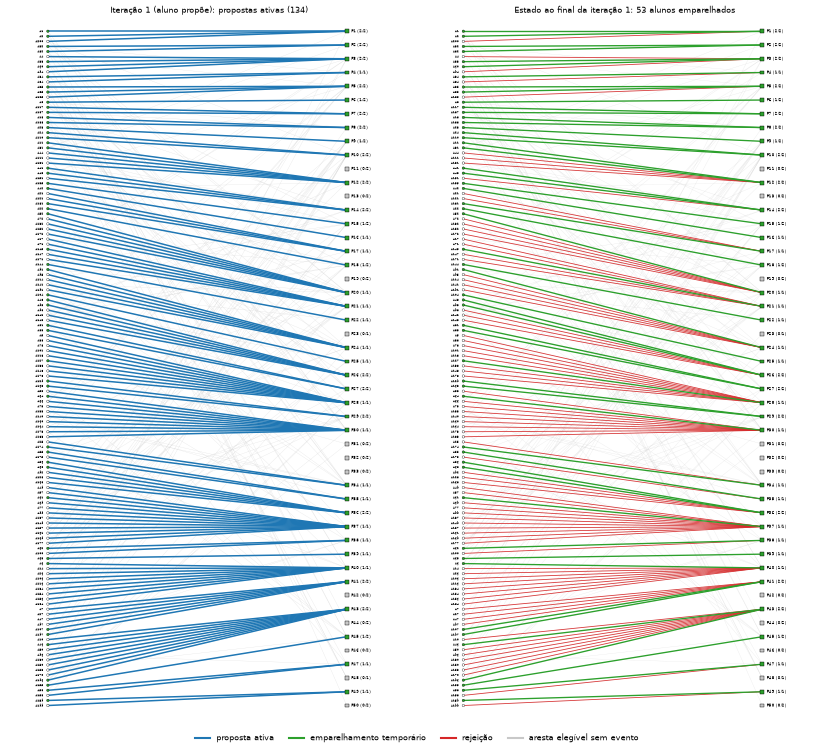


Iteração 2
  Alunos livres no início da iteração: 81
  Fase 1: propostas ativas 53, emparelhamentos temporários novos 8, rejeições 49
  Fase 2: não executada, a fase 1 ainda tinha propostas a fazer
  Ao final da iteração: 57 alunos emparelhados em 38 projetos


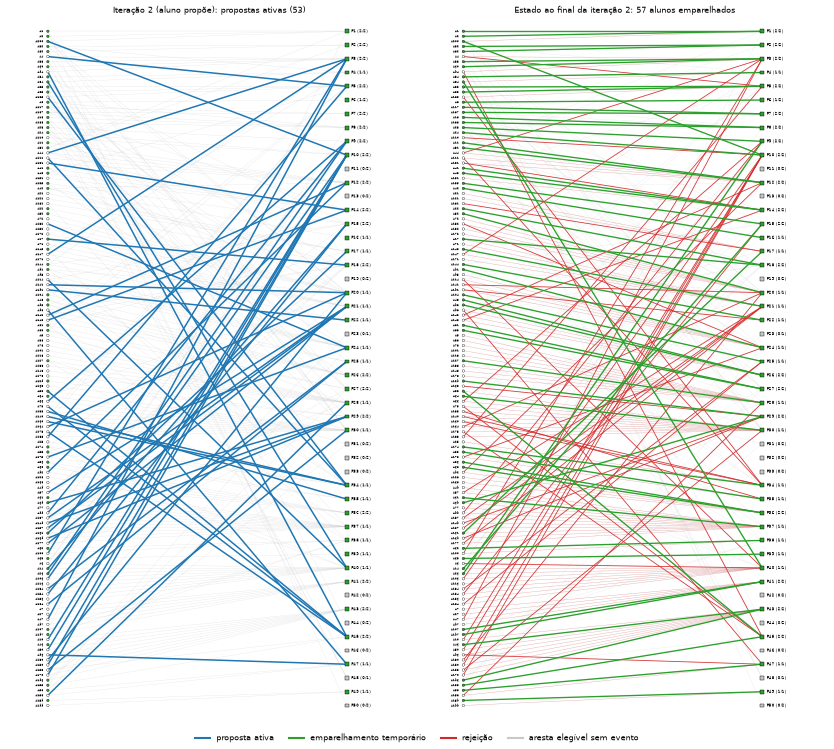


Iteração 3
  Alunos livres no início da iteração: 77
  Fase 1: propostas ativas 19, emparelhamentos temporários novos 4, rejeições 19
    Propostas: A6 propôs a P9; A44 propôs a P15; A57 propôs a P18; A66 propôs a P10; A98 propôs a P18; A100 propôs a P20; A114 propôs a P15; A137 propôs a P28; A140 propôs a P5; A142 propôs a P18; A143 propôs a P5; A149 propôs a P9; A153 propôs a P45; A157 propôs a P18; A160 propôs a P5; A169 propôs a P9; A177 propôs a P18; A181 propôs a P37; A191 propôs a P34
    Rejeições: A140 e P5; A143 e P5; A160 e P5; A26 e P9; A149 e P9; A169 e P9; A66 e P10; A44 e P15; A114 e P15; A22 e P18; A17 e P18; A57 e P18; A98 e P18; A142 e P18; A52 e P20; A137 e P28; A191 e P34; A181 e P37; A153 e P45
  Fase 2: não executada, a fase 1 ainda tinha propostas a fazer
  Ao final da iteração: 57 alunos emparelhados em 38 projetos


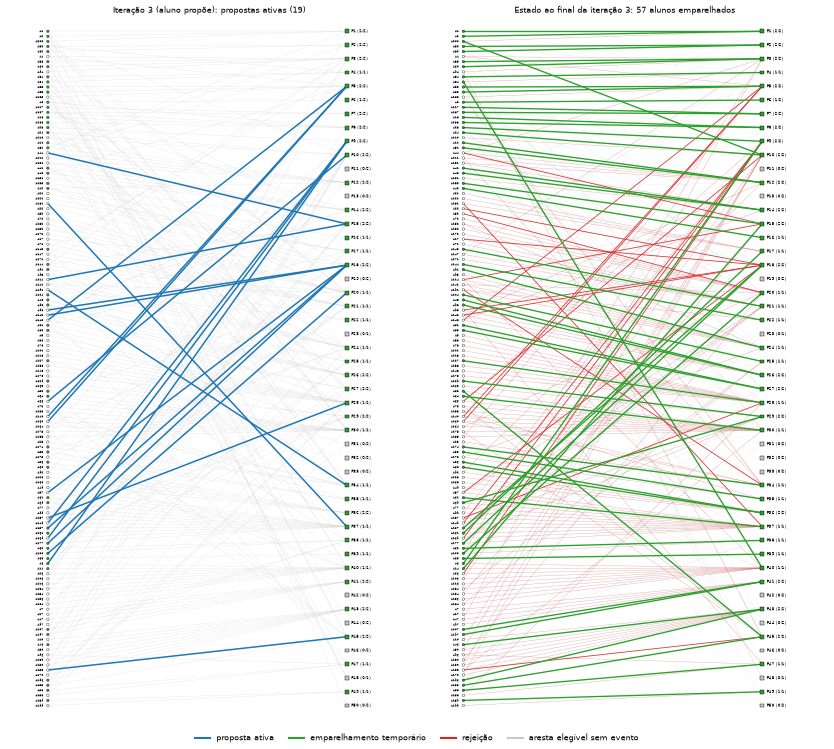


Iteração 4
  Alunos livres no início da iteração: 77
  Fase 1: propostas ativas 1, emparelhamentos temporários novos 0, rejeições 1
    Propostas: A26 propôs a P15
    Rejeições: A26 e P15
  Fase 2: não executada, a fase 1 ainda tinha propostas a fazer
  Ao final da iteração: 57 alunos emparelhados em 38 projetos


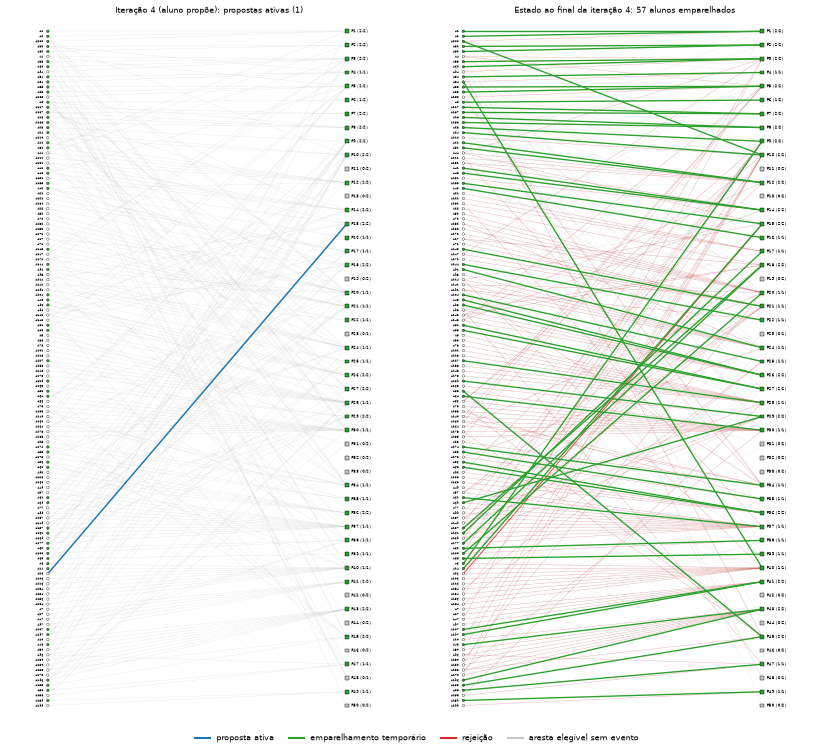


Iteração 5
  Alunos livres no início da iteração: 77
  Fase 1: propostas ativas 0, emparelhamentos temporários novos 0, rejeições 0
  Fase 2: caminho aumentante com 2 alunos: A137 entra em P28; A127 sai de P28 e entra em P31
  Ao final da iteração: 58 alunos emparelhados em 39 projetos


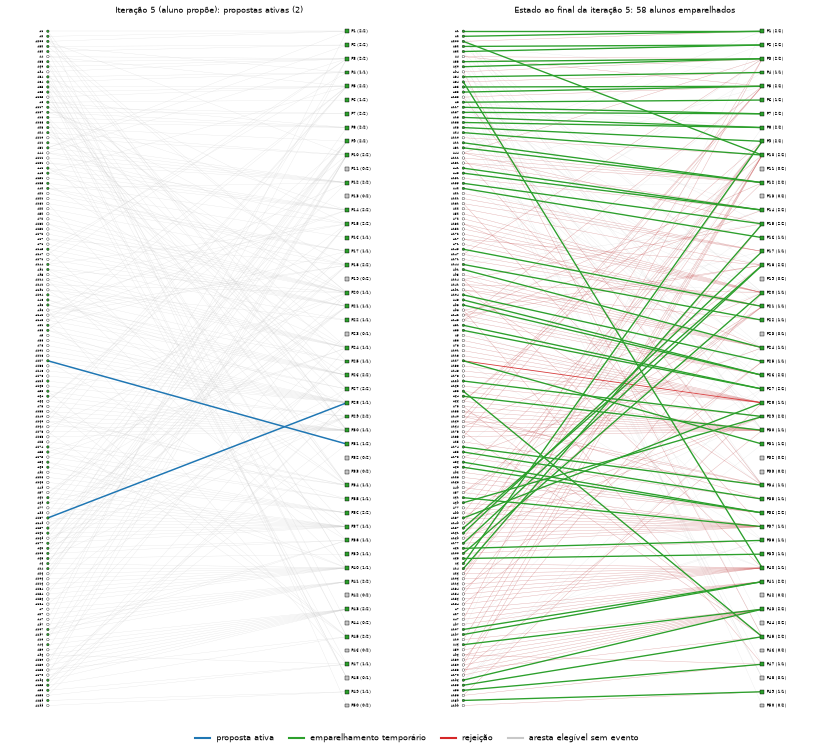


Iteração 6
  Alunos livres no início da iteração: 76
  Fase 1: propostas ativas 0, emparelhamentos temporários novos 0, rejeições 0
  Fase 2: caminho aumentante com 3 alunos: A10 entra em P10; A200 sai de P10 e entra em P1; A1 sai de P1 e entra em P50
  Ao final da iteração: 59 alunos emparelhados em 40 projetos


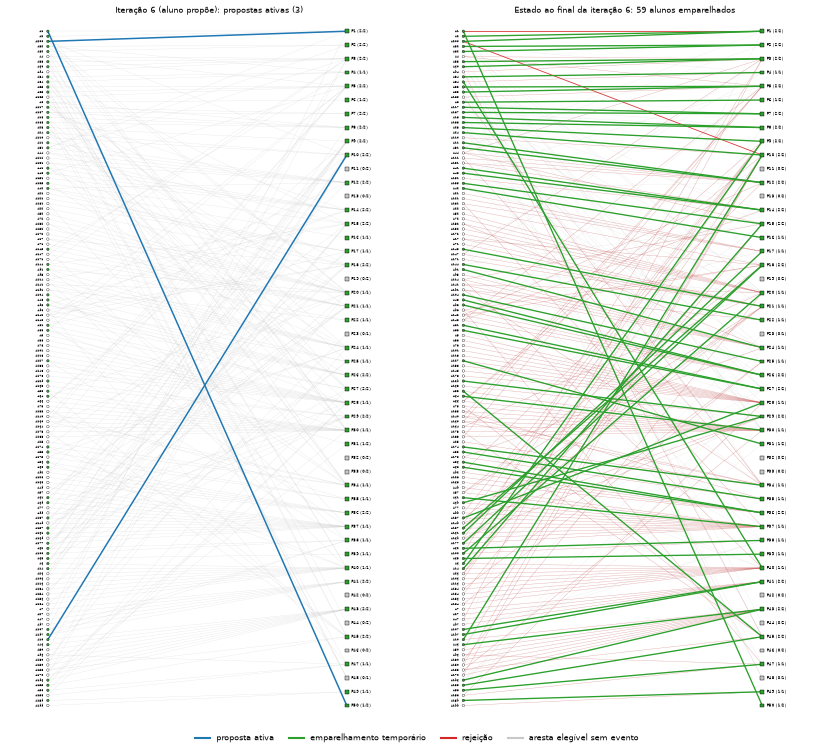


Iteração 7
  Alunos livres no início da iteração: 75
  Fase 1: propostas ativas 0, emparelhamentos temporários novos 0, rejeições 0
  Fase 2: caminho aumentante com 4 alunos: A52 entra em P20; A100 sai de P20 e entra em P38; A62 sai de P38 e entra em P8; A188 sai de P8 e entra em P48
  Ao final da iteração: 60 alunos emparelhados em 41 projetos


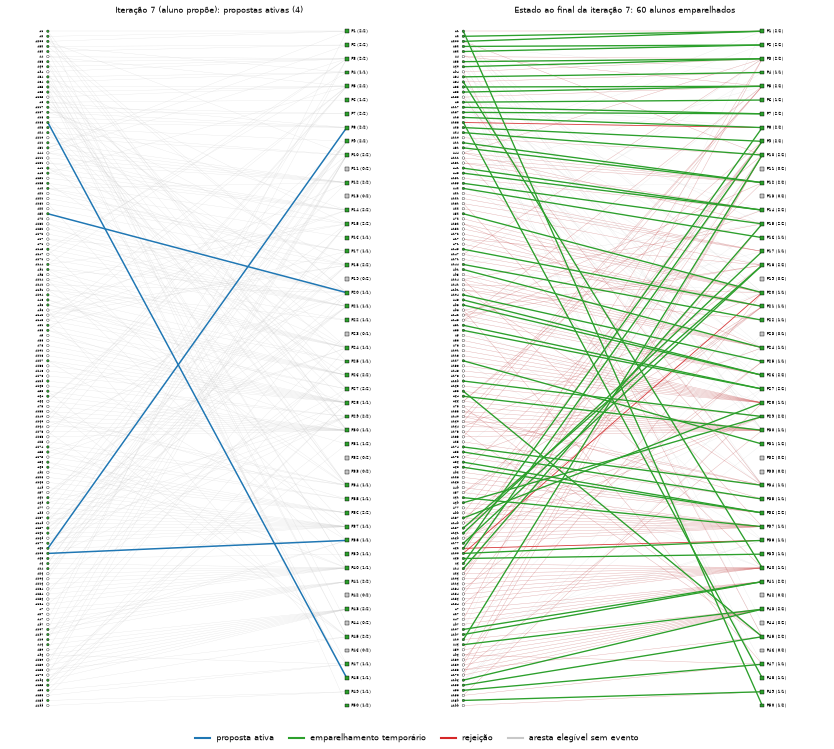


Iteração 8
  Alunos livres no início da iteração: 74
  Fase 1: propostas ativas 0, emparelhamentos temporários novos 0, rejeições 0
  Fase 2: nenhum caminho aumentante estável a partir dos 74 alunos livres
  Ao final da iteração: 60 alunos emparelhados em 41 projetos


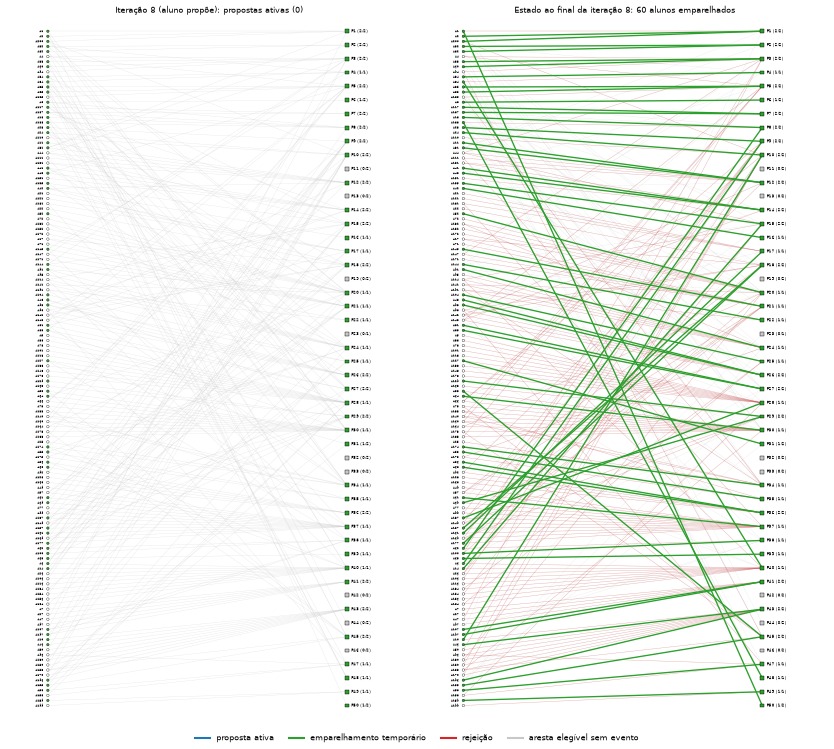


Iteração 9
  Alunos livres no início da iteração: 74
  Fase 1: propostas ativas 0, emparelhamentos temporários novos 0, rejeições 0
  Fase 2: nenhum caminho aumentante estável a partir dos 74 alunos livres
  Ao final da iteração: 60 alunos emparelhados em 41 projetos


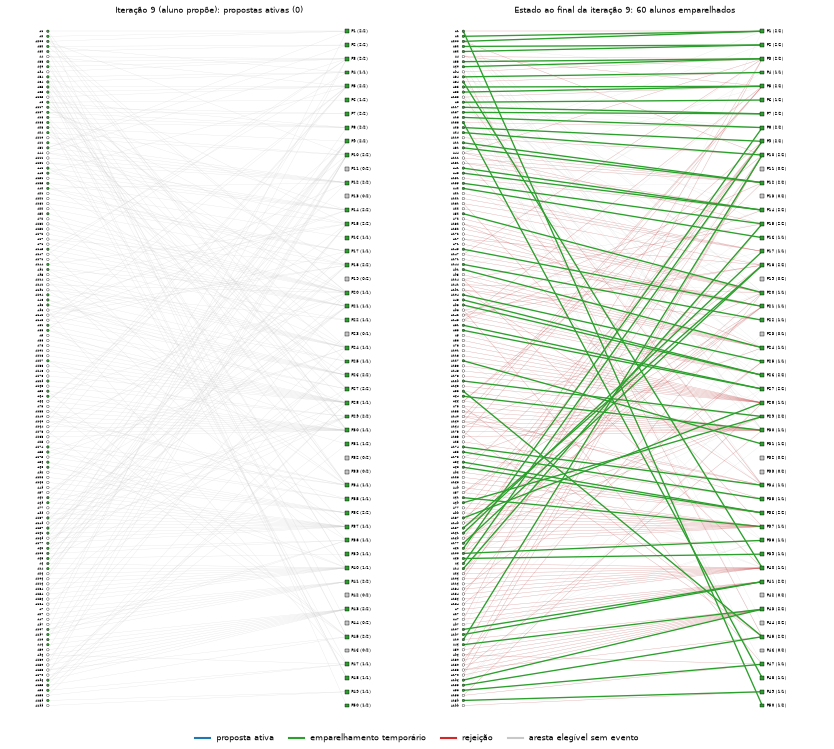


Iteração 10
  Alunos livres no início da iteração: 74
  Fase 1: propostas ativas 0, emparelhamentos temporários novos 0, rejeições 0
  Fase 2: nenhum caminho aumentante estável a partir dos 74 alunos livres
  Ao final da iteração: 60 alunos emparelhados em 41 projetos


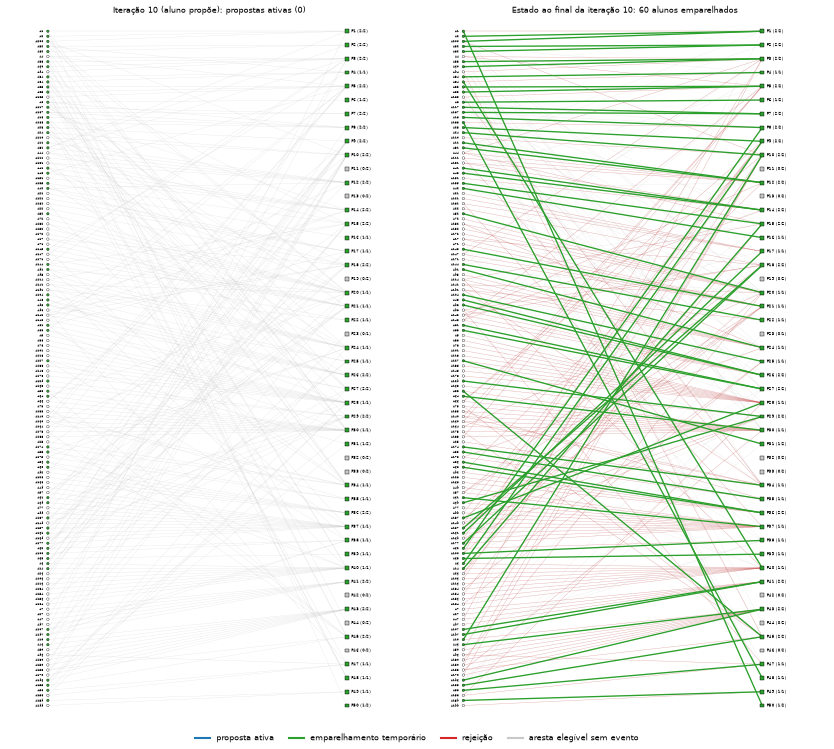


Evolução do emparelhamento (aluno propõe):


,Iteração,Propostas,Rejeições,Caminho aumentante (alunos),Alunos emparelhados,Projetos com aluno
0,1,134,81,0,53,38
1,2,53,49,0,57,38
2,3,19,19,0,57,38
3,4,1,1,0,57,38
4,5,0,0,2,58,39
5,6,0,0,3,59,40
6,7,0,0,4,60,41
7,8,0,0,0,60,41
8,9,0,0,0,60,41
9,10,0,0,0,60,41


Laço estacionário ao final das iterações: True


In [32]:
resaluno = executaremostrar(I, 'aluno')
print('Evolução do emparelhamento (aluno propõe):')
display(tabelaevolucao(resaluno))
print('Laço estacionário ao final das iterações:', resaluno['convergiu'])

## **Etapa 7.** Simulação B: o projeto propõe (proposta final)

Esta é a versão orientada ao projeto (lecturer-oriented). Os projetos propõem aos alunos na ordem da sua lista de preferência, e a fase 1 devolve a alocação estável mais favorável aos projetos. Como pede o enunciado, esta é a proposta final, e a matriz de emparelhamento das próximas etapas sai dela.

Iteração 1
  Alunos livres no início da iteração: 134
  Fase 1: propostas ativas 63, emparelhamentos temporários novos 44, rejeições 19
    Rejeições: A1 e P50; A18 e P47; A23 e P29; A32 e P20; A33 e P45; A34 e P15; A34 e P40; A35 e P24; A35 e P48; A60 e P34; A61 e P17; A63 e P29; A82 e P44; A117 e P18; A127 e P31; A144 e P15; A187 e P14; A196 e P31; A197 e P23
  Fase 2: não executada, a fase 1 ainda tinha propostas a fazer
  Ao final da iteração: 44 alunos emparelhados em 30 projetos


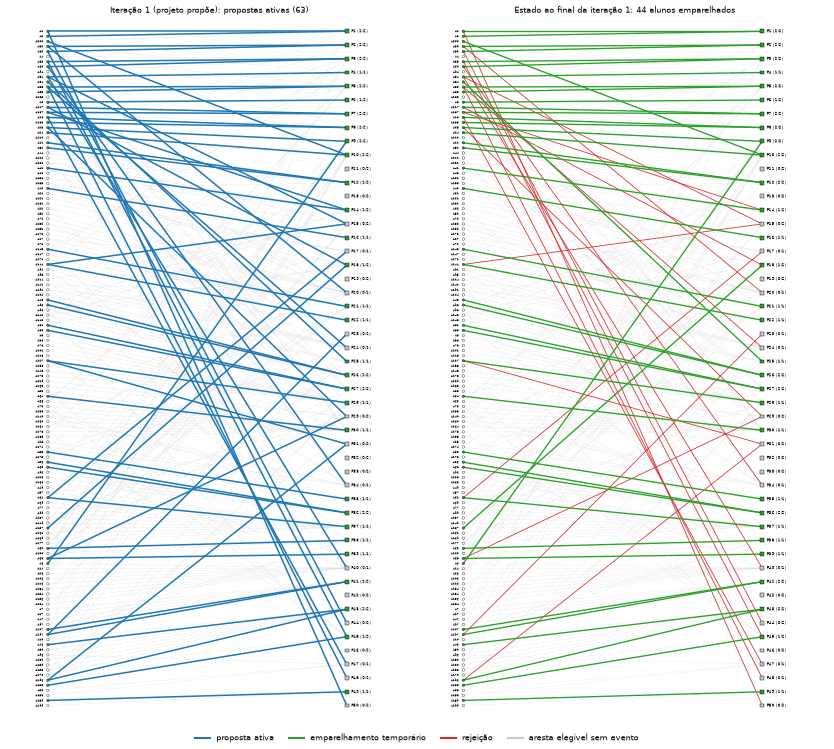


Iteração 2
  Alunos livres no início da iteração: 90
  Fase 1: propostas ativas 14, emparelhamentos temporários novos 10, rejeições 5
    Propostas: P14 propôs a A43; P15 propôs a A135; P15 propôs a A14; P17 propôs a A81; P18 propôs a A177; P20 propôs a A64; P24 propôs a A91; P29 propôs a A69; P29 propôs a A129; P34 propôs a A85; P40 propôs a A84; P45 propôs a A53; P47 propôs a A58; P48 propôs a A85
    Rejeições: A64 e P20; A81 e P17; A84 e P25; A85 e P34; A85 e P48
  Fase 2: não executada, a fase 1 ainda tinha propostas a fazer
  Ao final da iteração: 53 alunos emparelhados em 34 projetos


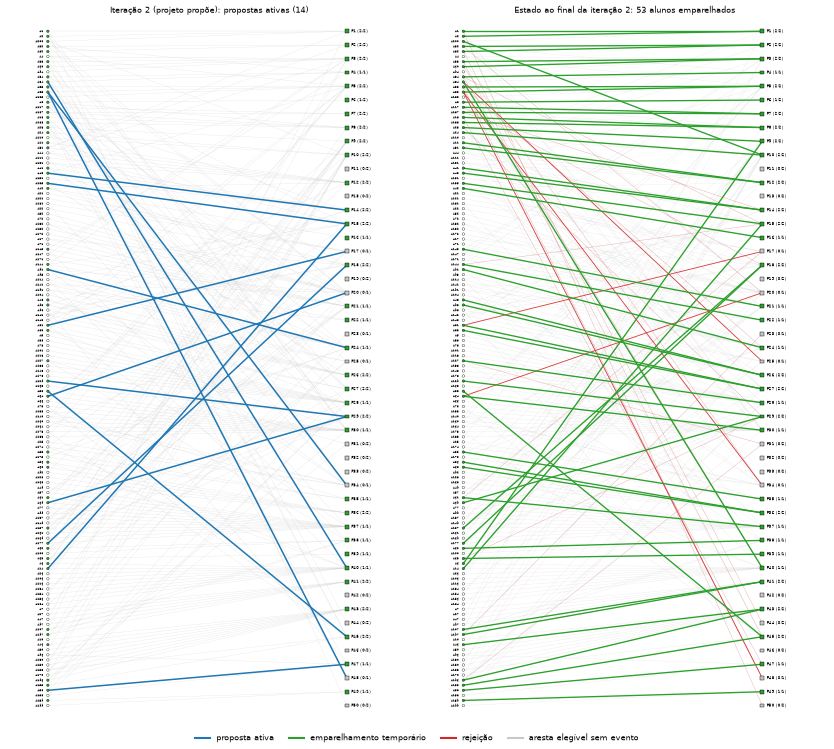


Iteração 3
  Alunos livres no início da iteração: 81
  Fase 1: propostas ativas 5, emparelhamentos temporários novos 3, rejeições 2
    Propostas: P17 propôs a A161; P20 propôs a A100; P25 propôs a A93; P34 propôs a A174; P48 propôs a A188
    Rejeições: A93 e P25; A188 e P48
  Fase 2: não executada, a fase 1 ainda tinha propostas a fazer
  Ao final da iteração: 56 alunos emparelhados em 37 projetos


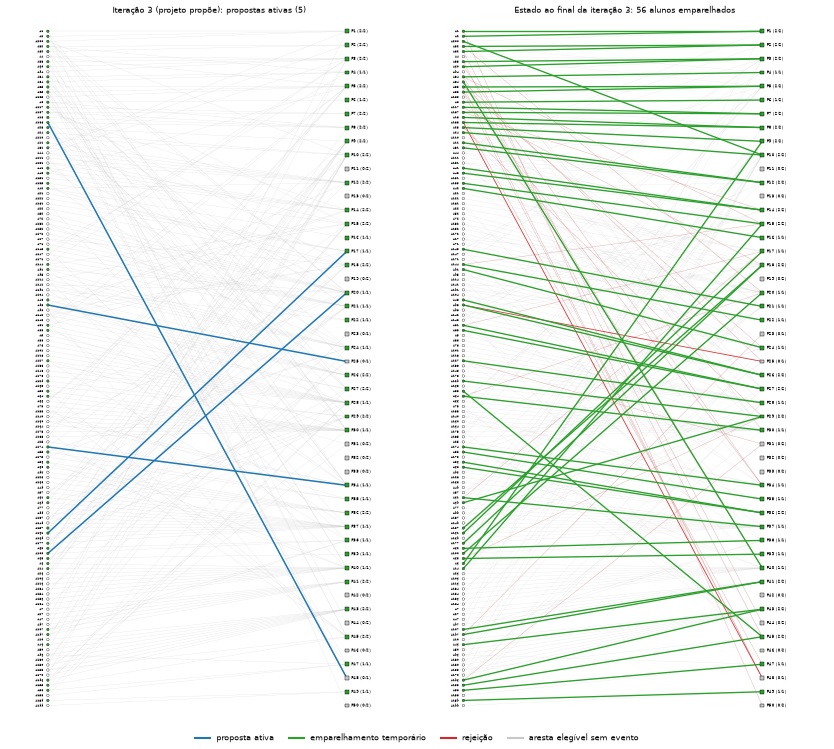


Iteração 4
  Alunos livres no início da iteração: 78
  Fase 1: propostas ativas 1, emparelhamentos temporários novos 1, rejeições 0
    Propostas: P25 propôs a A104
  Fase 2: não executada, a fase 1 ainda tinha propostas a fazer
  Ao final da iteração: 57 alunos emparelhados em 38 projetos


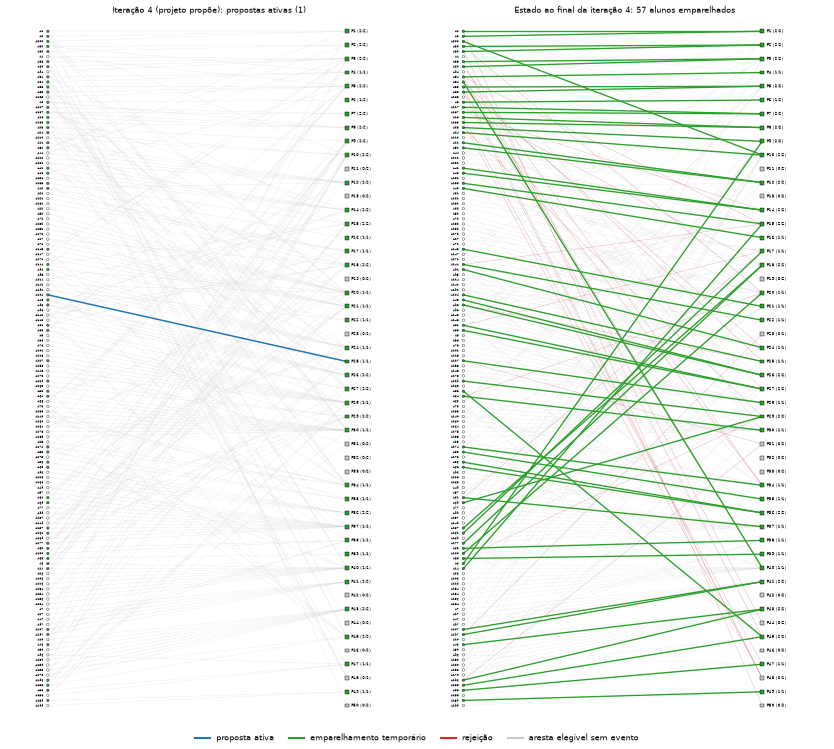


Iteração 5
  Alunos livres no início da iteração: 77
  Fase 1: propostas ativas 0, emparelhamentos temporários novos 0, rejeições 0
  Fase 2: caminho aumentante com 2 alunos: A137 entra em P28; A127 sai de P28 e entra em P31
  Ao final da iteração: 58 alunos emparelhados em 39 projetos


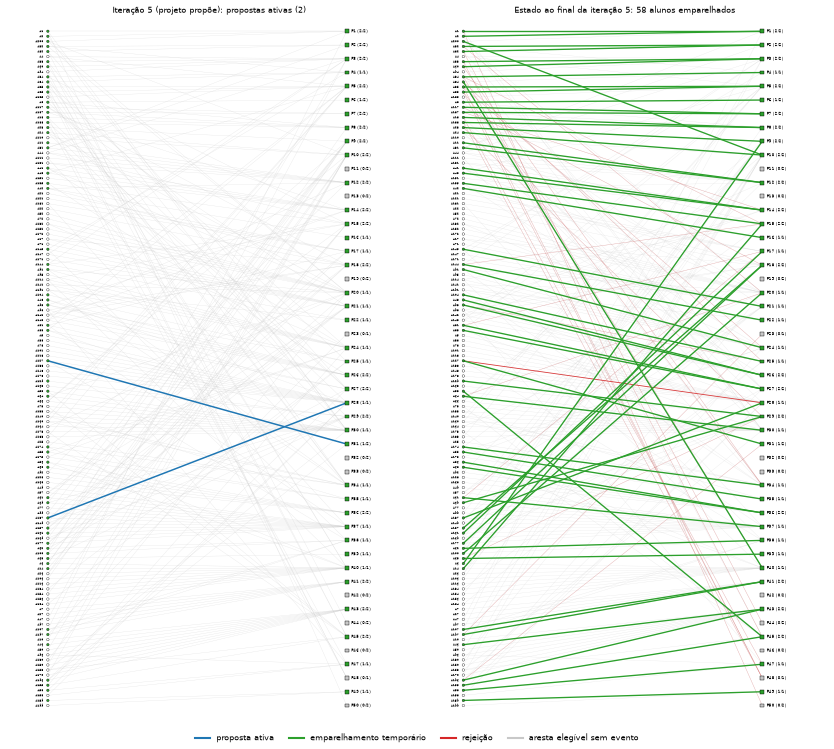


Iteração 6
  Alunos livres no início da iteração: 76
  Fase 1: propostas ativas 0, emparelhamentos temporários novos 0, rejeições 0
  Fase 2: caminho aumentante com 3 alunos: A10 entra em P10; A200 sai de P10 e entra em P1; A1 sai de P1 e entra em P50
  Ao final da iteração: 59 alunos emparelhados em 40 projetos


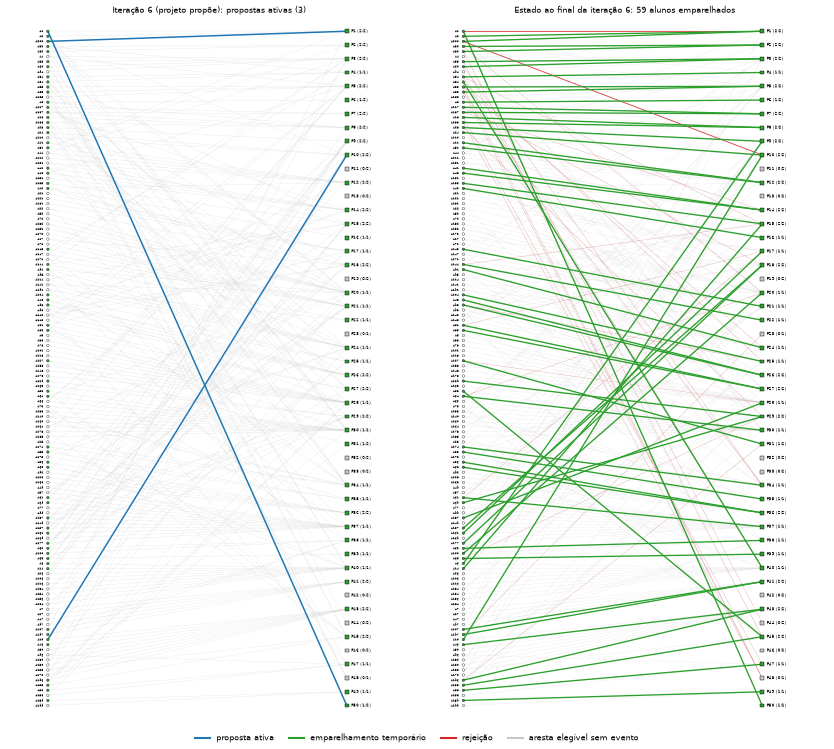


Iteração 7
  Alunos livres no início da iteração: 75
  Fase 1: propostas ativas 0, emparelhamentos temporários novos 0, rejeições 0
  Fase 2: caminho aumentante com 4 alunos: A52 entra em P20; A100 sai de P20 e entra em P38; A62 sai de P38 e entra em P8; A188 sai de P8 e entra em P48
  Ao final da iteração: 60 alunos emparelhados em 41 projetos


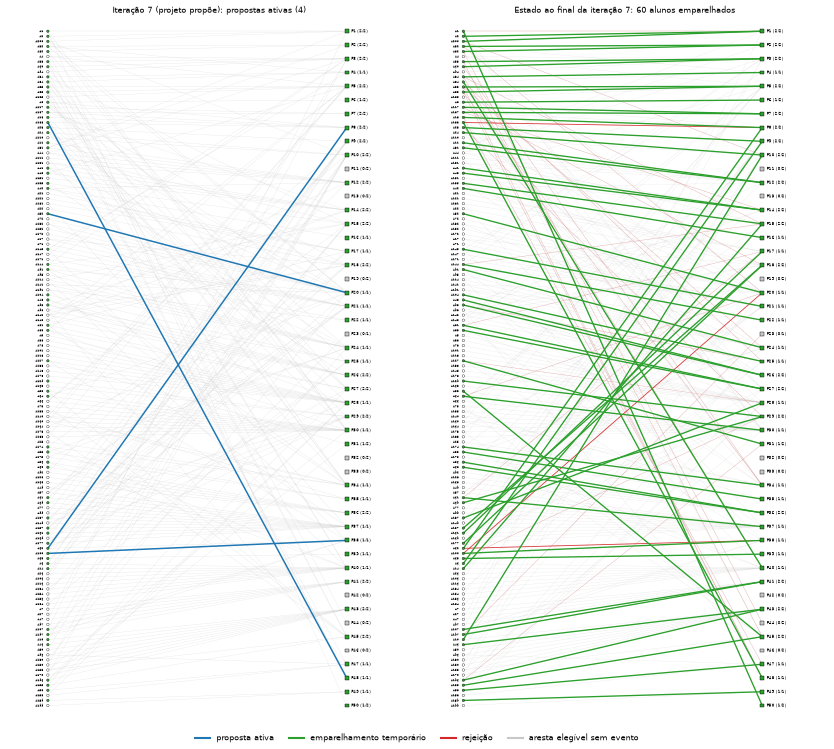


Iteração 8
  Alunos livres no início da iteração: 74
  Fase 1: propostas ativas 0, emparelhamentos temporários novos 0, rejeições 0
  Fase 2: nenhum caminho aumentante estável a partir dos 74 alunos livres
  Ao final da iteração: 60 alunos emparelhados em 41 projetos


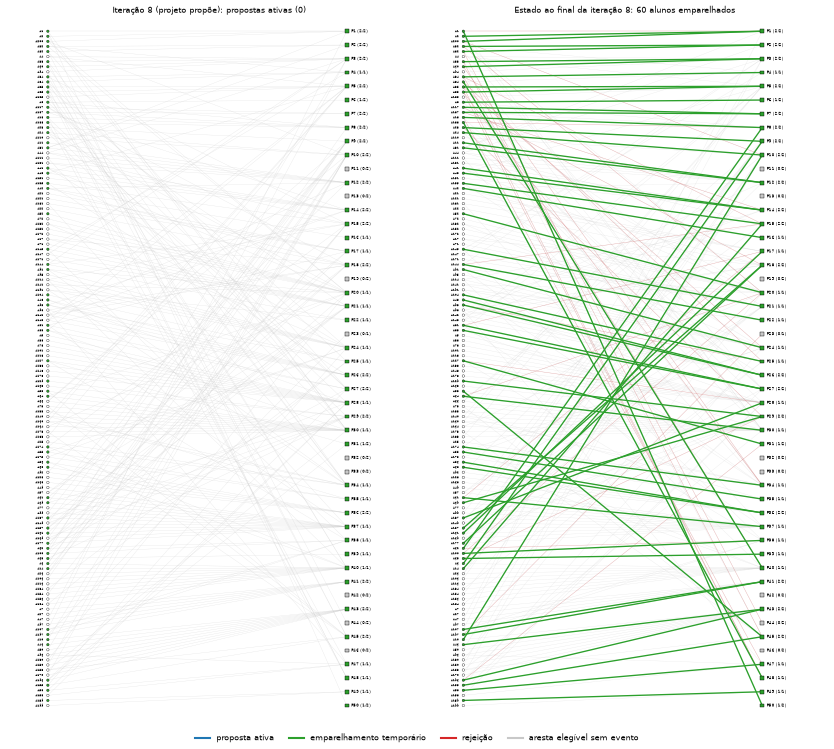


Iteração 9
  Alunos livres no início da iteração: 74
  Fase 1: propostas ativas 0, emparelhamentos temporários novos 0, rejeições 0
  Fase 2: nenhum caminho aumentante estável a partir dos 74 alunos livres
  Ao final da iteração: 60 alunos emparelhados em 41 projetos


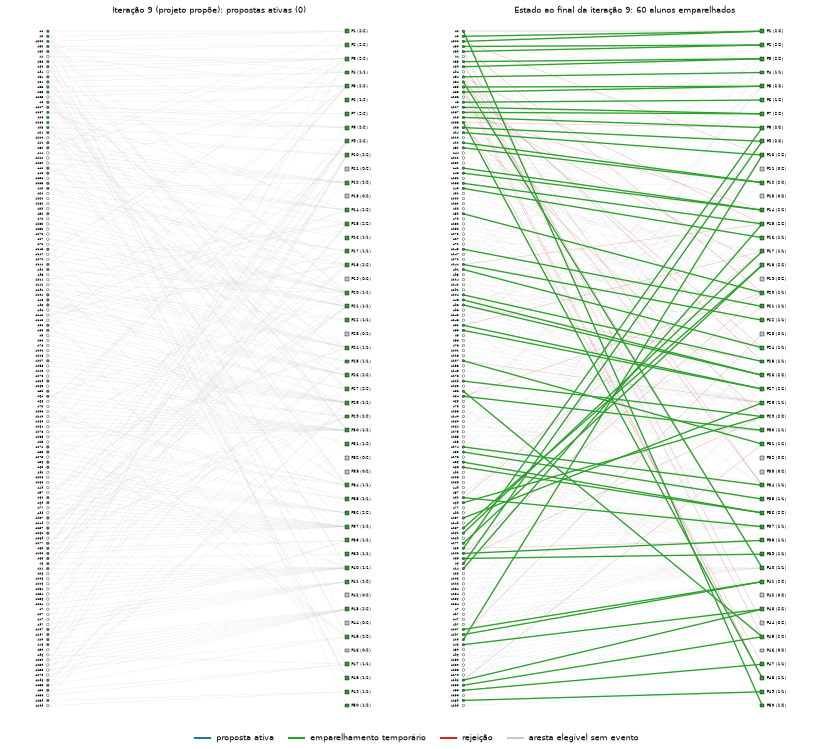


Iteração 10
  Alunos livres no início da iteração: 74
  Fase 1: propostas ativas 0, emparelhamentos temporários novos 0, rejeições 0
  Fase 2: nenhum caminho aumentante estável a partir dos 74 alunos livres
  Ao final da iteração: 60 alunos emparelhados em 41 projetos


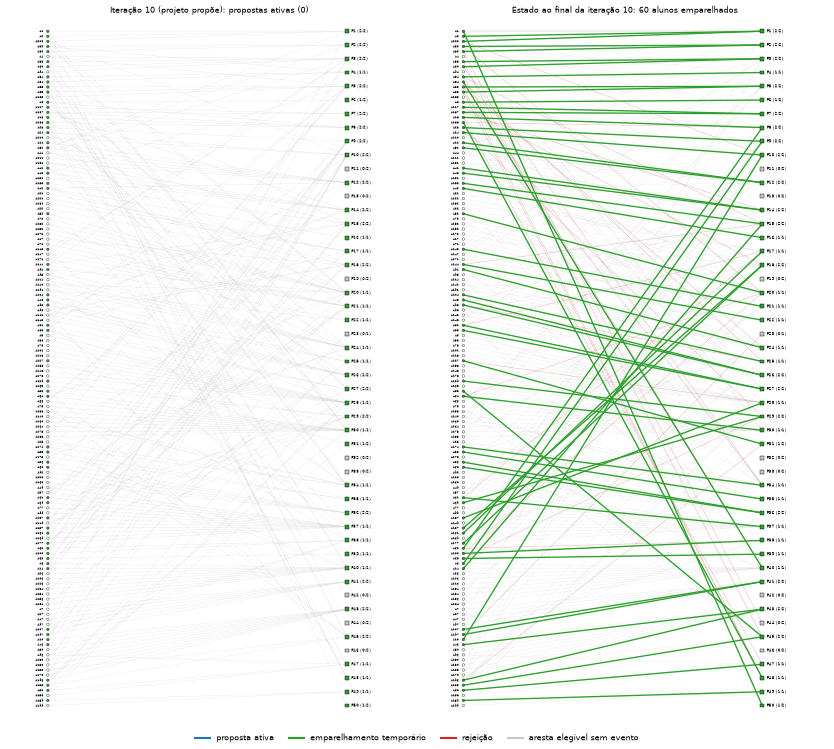


Evolução do emparelhamento (projeto propõe):


,Iteração,Propostas,Rejeições,Caminho aumentante (alunos),Alunos emparelhados,Projetos com aluno
0,1,63,19,0,44,30
1,2,14,5,0,53,34
2,3,5,2,0,56,37
3,4,1,0,0,57,38
4,5,0,0,2,58,39
5,6,0,0,3,59,40
6,7,0,0,4,60,41
7,8,0,0,0,60,41
8,9,0,0,0,60,41
9,10,0,0,0,60,41


Laço estacionário ao final das iterações: True


In [33]:
resprojeto = executaremostrar(I, 'projeto')
print('Evolução do emparelhamento (projeto propõe):')
display(tabelaevolucao(resprojeto))
print('Laço estacionário ao final das iterações:', resprojeto['convergiu'])

## **Etapa 8.** Verificação de estabilidade e comparação das duas simulações

Aqui conferimos o que o algoritmo prometeu. Para cada resultado contamos os pares bloqueantes nos dois sentidos de estabilidade e verificamos que nenhum projeto passou da capacidade e que nenhum aluno foi alocado em projeto fora da sua lista elegível.

Os resultados são comparados em dois momentos: no fim da fase 1 (aceitação adiada pura, estável no sentido estrito) e no fim do laço (depois dos caminhos aumentantes, estável no sentido fraco). Pode haver pares bloqueantes no sentido estrito depois da fase 2. Isso é esperado e acontece só entre alunos de mesma nota, em que o desempate da lista estrita prefere um e o caminho aumentante escolheu o outro. A coluna de pares fracos tem de ser zero.

,alunos,projetos com aluno,respeita vagas,só projetos da lista,pares bloqueantes estritos,pares bloqueantes fracos,1ª escolha,2ª escolha,3ª escolha,posição relativa média na lista do projeto
"Aluno propõe, fim da fase 1",57,38,True,True,0,0,42,8,7,0.331
"Aluno propõe, fim do laço",60,41,True,True,4,0,40,9,11,0.384
"Projeto propõe, fim da fase 1",57,38,True,True,0,0,42,8,7,0.331
"Projeto propõe, fim do laço",60,41,True,True,4,0,40,9,11,0.384


Pares bloqueantes estritos que sobram no fim do laço (proposta final):
  A1 (nota 5) e P1 (alunos de P1 com notas [5, 5]): empate de nota com o pior aluno, não é bloqueio fraco
  A62 (nota 5) e P38 (alunos de P38 com notas [5]): empate de nota com o pior aluno, não é bloqueio fraco
  A127 (nota 5) e P28 (alunos de P28 com notas [5]): empate de nota com o pior aluno, não é bloqueio fraco
  A188 (nota 5) e P8 (alunos de P8 com notas [5, 5]): empate de nota com o pior aluno, não é bloqueio fraco
As duas versões coincidem no fim da fase 1? True
As duas versões coincidem no fim do laço? True
Alunos que recebem projeto diferente nas duas versões: nenhum


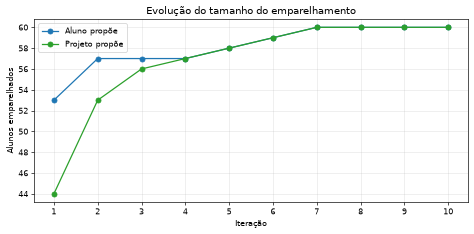

In [34]:
def verificar(I, par):
    cont = Counter(par.values())
    return {'alunos': len(par),
            'projetos com aluno': len(cont),
            'respeita vagas': all(cont[p] <= I.vagas[p] for p in cont),
            'só projetos da lista': all(p in I.prefs[a] for a, p in par.items()),
            'pares bloqueantes estritos': len(paresbloqueantes(I, par, fraca=False)),
            'pares bloqueantes fracos': len(paresbloqueantes(I, par, fraca=True))}


def estatisticasescolha(I, par):
    ordens = Counter(I.escolha[a][p] for a, p in par.items())
    rel = [I.pos[p][a] / len(I.lista[p]) for a, p in par.items()]
    return {'1ª escolha': ordens[1], '2ª escolha': ordens[2], '3ª escolha': ordens[3],
            'posição relativa média na lista do projeto': round(float(np.mean(rel)), 3)}


linhas = {}
for nome, res in (('Aluno propõe', resaluno), ('Projeto propõe', resprojeto)):
    linhas[f'{nome}, fim da fase 1'] = {**verificar(I, res['parda']), **estatisticasescolha(I, res['parda'])}
    linhas[f'{nome}, fim do laço'] = {**verificar(I, res['par']), **estatisticasescolha(I, res['par'])}
dfcomp = pd.DataFrame(linhas).T
display(dfcomp)

# os pares bloqueantes estritos que sobram depois da fase 2 têm que ser só empates da nota
restantes = paresbloqueantes(I, resprojeto['par'], fraca=False)
if restantes:
    ocupf = ocupantes(resprojeto['par'])
    print('Pares bloqueantes estritos que sobram no fim do laço (proposta final):')
    for a, p in restantes:
        notasp = sorted(I.nota[x] for x in ocupf[p])
        assert I.nota[a] <= min(notasp), 'um par estrito com nota maior seria bloqueio fraco'
        print(f"  A{a} (nota {I.nota[a]}) e P{p} (alunos de P{p} com notas {notasp}): empate de nota com o pior aluno, não é bloqueio fraco")
iguaisda = resaluno['parda'] == resprojeto['parda']
print('As duas versões coincidem no fim da fase 1?', iguaisda)
print('As duas versões coincidem no fim do laço?', resaluno['par'] == resprojeto['par'])
dif = sorted(a for a in set(resaluno['par']) | set(resprojeto['par']) if resaluno['par'].get(a) != resprojeto['par'].get(a))
print('Alunos que recebem projeto diferente nas duas versões:', ', '.join(f'A{a}' for a in dif) if dif else 'nenhum')

if MOSTRARGRAFICOS:
    fig, ax = plt.subplots(figsize=(8, 4))
    for nome, res, cor in (('Aluno propõe', resaluno, CORPROPOSTA), ('Projeto propõe', resprojeto, CORTEMPORARIO)):
        ax.plot([r['t'] for r in res['historico']], [r['tam'] for r in res['historico']], marker='o', label=nome, color=cor)
    ax.set_xlabel('Iteração')
    ax.set_ylabel('Alunos emparelhados')
    ax.set_title('Evolução do tamanho do emparelhamento')
    ax.set_xticks(range(1, NITERACOES + 1))
    ax.legend()
    ax.grid(alpha=0.3)
    plt.tight_layout()
    salvarfigura(fig, 'evolucao-tamanho')
    plt.show()

### **Etapa 8b.** Testes automáticos de corretude

A etapa 8 verifica o resultado desta instância. Aqui testamos o próprio algoritmo, com três grupos de testes.

1. **Sem aleatoriedade.** O enunciado exige que as iterações não sejam aleatórias. Rodamos a simulação uma segunda vez e comparamos as dez iterações campo a campo.
2. **Invariantes de cada iteração.** Em todas as iterações nenhum projeto passa das vagas e nenhum aluno está fora da sua lista elegível. O tamanho do emparelhamento nunca diminui. Na fase 1, quando o aluno propõe cada aluno só piora de escolha, e quando o projeto propõe cada aluno só melhora, que é a assinatura das duas versões do Gale-Shapley. O fim da fase 1 é estável no sentido estrito e o fim do laço é estável no sentido fraco.
3. **Contra força bruta.** Em 120 instâncias pequenas e fixas (semente 2026, só para gerar os testes, o algoritmo continua sem sorteio) enumeramos todas as alocações e achamos todas as estáveis. A versão em que o aluno propõe tem de devolver uma alocação estável que é a melhor para todos os alunos, e a versão em que o projeto propõe tem de devolver uma estável que é a pior para todos os alunos, o que é o mesmo que ser a melhor para os projetos. É o teorema clássico de Gale e Shapley, conferido por enumeração.

Se qualquer teste falhar, a célula interrompe a execução com a descrição do que falhou.

In [35]:
import itertools
import random


def fimfase1(res):
    return res['parda'] if res['parda'] is not None else res['par']


def monotonia(res, sentido):
    """Na fase 1, sentido=+1 exige que a ordem de escolha do aluno só piore (aluno propõe)
    e sentido=-1 exige que só melhore (projeto propõe). A fase 2 pode mover nos dois sentidos."""
    anterior = {}
    for rec in res['historico']:
        if rec['fase2'] is not None:
            break
        for a, p in rec['par'].items():
            e = I.escolha[a][p]
            if a in anterior and (e - anterior[a]) * sentido < 0:
                return False
            anterior[a] = e
    return True


def posto(J, par, a):
    return J.escolha[a][par[a]] if a in par else math.inf


def estaveis_forcabruta(J):
    """Todas as alocações estritamente estáveis de uma instância pequena."""
    ordem = sorted(J.alunos)
    achadas = []
    for combo in itertools.product(*[[None] + J.prefs[a] for a in ordem]):
        par = {a: p for a, p in zip(ordem, combo) if p is not None}
        cont = Counter(par.values())
        if all(cont[p] <= J.vagas[p] for p in cont) and not paresbloqueantes(J, par):
            achadas.append(par)
    return achadas


def instancia_pequena(rng):
    nproj = rng.randint(2, 3)
    pj = {p: {'vagas': rng.randint(1, 2), 'req': rng.choice([3, 4])} for p in range(1, nproj + 1)}
    al = {}
    for a in range(1, rng.randint(4, 6) + 1):
        al[a] = {'prefsoriginais': rng.sample(list(pj), rng.randint(1, nproj)), 'nota': rng.choice([3, 4, 5])}
    limparpreferencias(pj, al)
    return Instancia(pj, al, 'codigo')


def forcabruta_confere(n=120, semente=2026):
    rng = random.Random(semente)
    for _ in range(n):
        J = instancia_pequena(rng)
        S = estaveis_forcabruta(J)
        MA = fimfase1(simular(J, 'aluno', niter=25))
        MP = fimfase1(simular(J, 'projeto', niter=25))
        if MA not in S or MP not in S:
            return False
        for M in S:
            for a in J.alunos:
                if posto(J, MA, a) > posto(J, M, a) or posto(J, MP, a) < posto(J, M, a):
                    return False
    return True


testes = []


def registrar(nome, condicao, detalhe=''):
    testes.append({'Teste': nome, 'Resultado': 'passou' if condicao else 'FALHOU', 'Detalhe': detalhe})


for modo, res in (('aluno', resaluno), ('projeto', resprojeto)):
    rotulo = f'{modo} propõe'
    registrar(f'Sem aleatoriedade ({rotulo})', simular(I, modo)['historico'] == res['historico'],
              'segunda execução idêntica nas 10 iterações')
    cont_ok = all(all(c <= I.vagas[p] for p, c in Counter(r['par'].values()).items()) for r in res['historico'])
    registrar(f'Respeita as vagas em todas as iterações ({rotulo})', cont_ok)
    lista_ok = all(p in I.prefs[a] for r in res['historico'] for a, p in r['par'].items())
    registrar(f'Só projetos da lista elegível em todas as iterações ({rotulo})', lista_ok)
    tams = [r['tam'] for r in res['historico']]
    registrar(f'Tamanho nunca diminui ({rotulo})', all(x <= y for x, y in zip(tams, tams[1:])), f'tamanhos {tams}')
    registrar(f'Fase 1 só {"piora" if modo == "aluno" else "melhora"} a escolha de cada aluno ({rotulo})',
              monotonia(res, +1 if modo == 'aluno' else -1))
    registrar(f'Fim da fase 1 sem par bloqueante estrito ({rotulo})', not paresbloqueantes(I, fimfase1(res)))
    registrar(f'Fim do laço sem par bloqueante fraco ({rotulo})', not paresbloqueantes(I, res['par'], fraca=True))

registrar('Gale-Shapley contra força bruta em 120 instâncias pequenas', forcabruta_confere(),
          'aluno propõe = ótimo dos alunos, projeto propõe = ótimo dos projetos')

dftestes = pd.DataFrame(testes)
estilo = dftestes.style.hide(axis='index')
aplicar = estilo.map if hasattr(estilo, 'map') else estilo.applymap      # pandas >= 2.1 tem map
display(aplicar(lambda v: 'background-color: #c7e9c0' if v == 'passou' else ('background-color: #fcbba1' if v == 'FALHOU' else ''),
                subset=['Resultado']))
falhas = dftestes[dftestes['Resultado'] != 'passou']
assert falhas.empty, 'Testes que falharam:\n' + falhas.to_string()
print(f'{len(dftestes)} testes, todos passaram.')

Teste,Resultado,Detalhe
Sem aleatoriedade (aluno propõe),passou,segunda execução idêntica nas 10 iterações
Respeita as vagas em todas as iterações (aluno propõe),passou,
Só projetos da lista elegível em todas as iterações (aluno propõe),passou,
Tamanho nunca diminui (aluno propõe),passou,"tamanhos [53, 57, 57, 57, 58, 59, 60, 60, 60, 60]"
Fase 1 só piora a escolha de cada aluno (aluno propõe),passou,
Fim da fase 1 sem par bloqueante estrito (aluno propõe),passou,
Fim do laço sem par bloqueante fraco (aluno propõe),passou,
Sem aleatoriedade (projeto propõe),passou,segunda execução idêntica nas 10 iterações
Respeita as vagas em todas as iterações (projeto propõe),passou,
Só projetos da lista elegível em todas as iterações (projeto propõe),passou,


15 testes, todos passaram.


### **Etapa 8c.** Animação da evolução

Para acompanhar o laço sem passar figura por figura, montamos um GIF com as dez iterações de cada versão, usando a mesma figura de duas vistas da etapa 5. Cada quadro é uma iteração, e o último quadro fica parado por mais tempo. Os arquivos são `evolucao-aluno-propoe.gif` e `evolucao-projeto-propoe.gif`, na pasta de figuras.

In [36]:
def montaranimacao(I, res, modo, duracaoms=1500, dpi=80):
    """Junta as figuras das iterações em um GIF e devolve o caminho do arquivo."""
    quadros = []
    for rec in res['historico']:
        fig = montariteracao(I, rec, modo)
        fig.set_dpi(dpi)
        fig.canvas.draw()
        quadros.append(Image.fromarray(np.ascontiguousarray(np.asarray(fig.canvas.buffer_rgba())[..., :3])))
        plt.close(fig)
    # um GIF tem só 256 cores. Usamos uma paleta única para todos os quadros e reservamos
    # as cores das arestas, senão o vermelho das rejeições (poucos pixels) sairia desbotado.
    larg, alt = quadros[0].size
    mosaico = Image.new('RGB', (larg, alt * len(quadros)))
    for i, q in enumerate(quadros):
        mosaico.paste(q, (0, i * alt))
    paleta = mosaico.quantize(colors=240, method=Image.Quantize.MEDIANCUT, dither=Image.Dither.NONE).getpalette()[:240 * 3]
    for cor in (CORPROPOSTA, CORTEMPORARIO, CORREJEICAO, CORFUNDO, '#000000', '#ffffff'):
        paleta += [int(cor[k:k + 2], 16) for k in (1, 3, 5)]
    paleta += [0] * (768 - len(paleta))
    modelo = Image.new('P', (1, 1))
    modelo.putpalette(paleta)
    quadros = [q.quantize(palette=modelo, dither=Image.Dither.NONE) for q in quadros]
    os.makedirs(PASTAFIGURAS, exist_ok=True)
    caminho = os.path.join(PASTAFIGURAS, f'evolucao-{modo}-propoe.gif')
    tempos = [duracaoms] * (len(quadros) - 1) + [4 * duracaoms]
    quadros[0].save(caminho, save_all=True, append_images=quadros[1:], duration=tempos, loop=0)
    return caminho


if MOSTRARGRAFICOS and GERARANIMACAO and SALVARSAIDAS:
    for modo, res in (('aluno', resaluno), ('projeto', resprojeto)):
        caminho = montaranimacao(I, res, modo)
        print(f'{caminho}: {os.path.getsize(caminho) / 1e6:.1f} MB, {len(res["historico"])} quadros')
else:
    print('Animação não gerada (precisa de MOSTRARGRAFICOS, GERARANIMACAO e SALVARSAIDAS ligados).')

..\figuras\evolucao-aluno-propoe.gif: 0.7 MB, 10 quadros
..\figuras\evolucao-projeto-propoe.gif: 0.5 MB, 10 quadros


## **Etapa 9.** Matriz final de emparelhamentos

Para cada aluno alocado mostramos os dois lados do "ganho" ou "perda", como pede o enunciado. A coluna da classificação do aluno diz em que posição o aluno ficou na lista de preferência do projeto e quantos alunos havia nela. A coluna da classificação do projeto diz qual foi a escolha do aluno que levou àquele projeto, na ordem em que o aluno escreveu a lista. Posição 1 em uma coluna e escolha 1 na outra significa que os dois lados ficaram com o melhor que podiam esperar.

A figura seguinte desenha a mesma informação como matriz: cada linha é um aluno alocado e cada coluna é um projeto realizado. O número dentro da célula verde é a ordem de escolha do aluno. As células cinza claro marcam outras arestas elegíveis do aluno que não foram usadas.

,Aluno,Nota,Projeto emparelhado,Classificação do aluno (lista de preferência do projeto),Classificação do projeto (lista de preferência do aluno)
0,A2,5,P1,2º (Top 2 de 5 alunos na lista P1),1º (Primeira escolha do aluno A2)
1,A200,5,P1,3º (Top 3 de 5 alunos na lista P1),1º (Primeira escolha do aluno A200)
2,A32,5,P2,1º (Top 1 de 3 alunos na lista P2),1º (Primeira escolha do aluno A32)
3,A82,5,P2,2º (Top 2 de 3 alunos na lista P2),1º (Primeira escolha do aluno A82)
4,A33,5,P3,1º (Top 1 de 9 alunos na lista P3),1º (Primeira escolha do aluno A33)
5,A60,5,P3,2º (Top 2 de 9 alunos na lista P3),1º (Primeira escolha do aluno A60)
6,A34,5,P4,1º (Top 1 de 4 alunos na lista P4),1º (Primeira escolha do aluno A34)
7,A35,5,P5,1º (Top 1 de 10 alunos na lista P5),1º (Primeira escolha do aluno A35)
8,A85,5,P5,2º (Top 2 de 10 alunos na lista P5),1º (Primeira escolha do aluno A85)
9,A8,5,P6,1º (Top 1 de 1 aluno na lista P6),1º (Primeira escolha do aluno A8)


Alunos alocados na 1ª escolha: 40, na 2ª: 9, na 3ª: 11


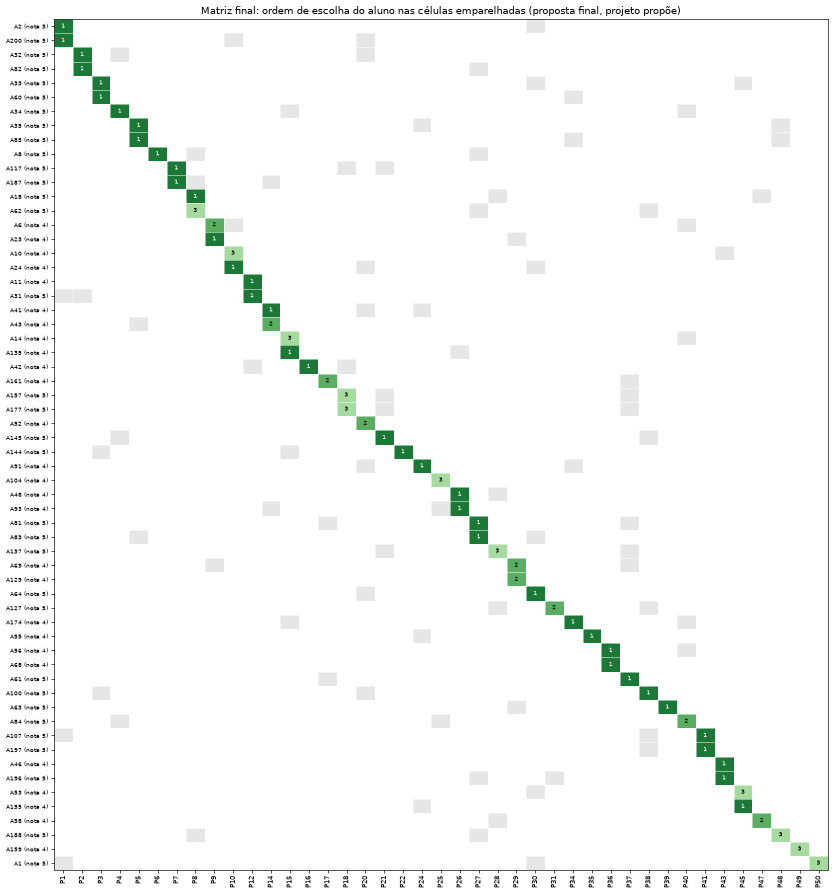

In [37]:
ORDINAL = {1: 'Primeira escolha', 2: 'Segunda escolha', 3: 'Terceira escolha'}


def matrizfinal(I, par):
    linhas = []
    for a in sorted(par, key=lambda a: (par[a], a)):
        p = par[a]
        pos, n, e = I.pos[p][a], len(I.lista[p]), I.escolha[a][p]
        linhas.append({'Aluno': f'A{a}', 'Nota': I.nota[a], 'Projeto emparelhado': f'P{p}',
                       'Classificação do aluno (lista de preferência do projeto)': f"{pos}º (Top {pos} de {n} {'aluno' if n == 1 else 'alunos'} na lista P{p})",
                       'Classificação do projeto (lista de preferência do aluno)': f'{e}º ({ORDINAL[e]} do aluno A{a})'})
    return pd.DataFrame(linhas)


def desenharmatriz(I, par):
    alunosm = sorted(par, key=lambda a: (par[a], a))
    projs = sorted(set(par.values()))
    col = {p: j for j, p in enumerate(projs)}
    M = np.zeros((len(alunosm), len(projs)))
    for i, a in enumerate(alunosm):
        for p in I.prefs[a]:
            if p in col:
                M[i, col[p]] = 4                    # aresta elegível não usada
        M[i, col[par[a]]] = I.escolha[a][par[a]]    # emparelhada: 1, 2 ou 3
    cmap = ListedColormap(['white', '#1b7837', '#5aae61', '#a6dba0', '#e6e6e6'])
    fig, ax = plt.subplots(figsize=(14, 15))
    ax.imshow(M, cmap=cmap, norm=BoundaryNorm([-0.5, 0.5, 1.5, 2.5, 3.5, 4.5], 5), aspect='auto')
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            if 1 <= M[i, j] <= 3:
                ax.text(j, i, int(M[i, j]), ha='center', va='center', color='white' if M[i, j] == 1 else 'black', fontsize=7)
    ax.set_xticks(range(len(projs)))
    ax.set_xticklabels([f'P{p}' for p in projs], rotation=90, fontsize=8)
    ax.set_yticks(range(len(alunosm)))
    ax.set_yticklabels([f'A{a} (nota {I.nota[a]})' for a in alunosm], fontsize=7)
    ax.set_xticks(np.arange(-0.5, len(projs), 1), minor=True)
    ax.set_yticks(np.arange(-0.5, len(alunosm), 1), minor=True)
    ax.grid(which='minor', color='white', linewidth=0.6)
    ax.tick_params(which='minor', length=0)
    ax.set_title('Matriz final: ordem de escolha do aluno nas células emparelhadas (proposta final, projeto propõe)')
    plt.tight_layout()
    salvarfigura(fig, 'matriz-final')
    plt.show()


parfinal = resprojeto['par']
dfmatriz = matrizfinal(I, parfinal)
display(dfmatriz)
ordens = Counter(I.escolha[a][p] for a, p in parfinal.items())
print(f"Alunos alocados na 1ª escolha: {ordens[1]}, na 2ª: {ordens[2]}, na 3ª: {ordens[3]}")
if MOSTRARGRAFICOS:
    desenharmatriz(I, parfinal)

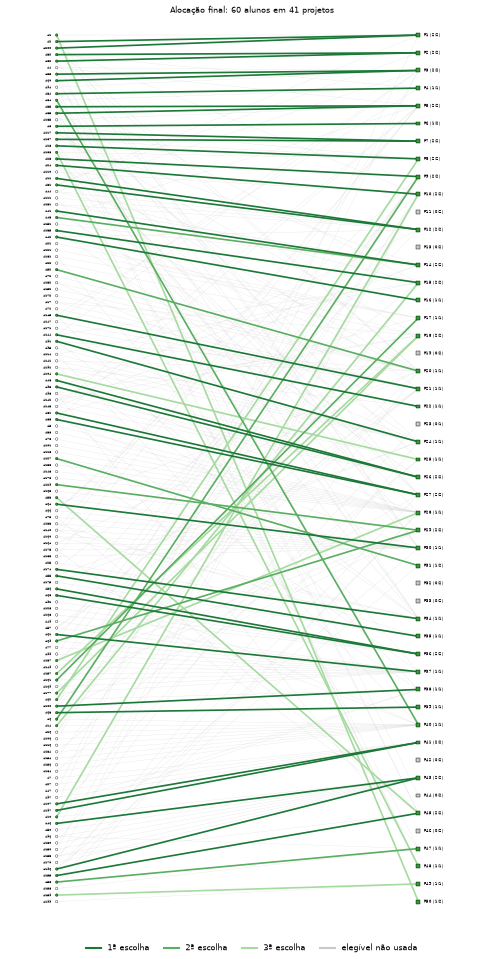

In [38]:
def desenharfinal(I, par):
    """Grafo bipartido da alocação final. Espessura e tom do verde seguem a ordem de escolha do aluno."""
    ys, yp = layoutbipartido(I, I.elegiveis)
    todas = [(a, p) for a in I.elegiveis for p in I.prefs[a]]
    porordem = {k: [(a, p) for a, p in par.items() if I.escolha[a][p] == k] for k in (1, 2, 3)}
    fig, ax = plt.subplots(figsize=(8.5, 16))
    desenharpainel(ax, I, ys, yp, par,
                    [(todas, CORFUNDO, 0.3, 0.6, 'solid'),
                     (porordem[3], '#a6dba0', 2.0, 1.0, 'solid'),
                     (porordem[2], '#5aae61', 2.0, 1.0, 'solid'),
                     (porordem[1], '#1b7837', 2.0, 1.0, 'solid')],
                    f'Alocação final: {len(par)} alunos em {len(set(par.values()))} projetos')
    legenda(fig, [('1ª escolha', '#1b7837', '-'), ('2ª escolha', '#5aae61', '-'),
                  ('3ª escolha', '#a6dba0', '-'), ('elegível não usada', CORFUNDO, '-')], 4)
    plt.tight_layout(rect=(0, 0.03, 1, 1))
    salvarfigura(fig, 'alocacao-final')
    plt.show()


if MOSTRARGRAFICOS:
    desenharfinal(I, parfinal)

### **Etapa 9b.** Ganho e perda de cada lado

O enunciado pede que a matriz mostre o "ganho" ou a "perda" de cada lado. A tabela da etapa 9 faz isso aluno por aluno. Aqui resumimos o conjunto em uma tabela e em uma figura de dois painéis.

No painel da esquerda, cada ponto é um aluno alocado. A posição horizontal é a posição relativa dele na lista do projeto (perto de 0 é o topo da lista, 1 é o fim) e a vertical é a ordem de escolha que o projeto teve para o aluno, com a primeira escolha em cima. O canto superior esquerdo é o ganho para os dois lados, o aluno foi para a sua primeira escolha e foi dos primeiros da lista do projeto. O painel da direita conta os mesmos alunos por faixa de posição, para ler a distribuição sem olhar ponto a ponto. Os pontos têm um pequeno deslocamento vertical fixo, calculado pela ordem de código, só para não ficarem uns sobre os outros.

Medida,Valor
Alunos alocados,60.000000
Lado do aluno: ordem de escolha média (1 é a melhor),1.520000
Lado do aluno: alocados na 1ª escolha (%),66.700000
Lado do aluno: alocados na 1ª ou 2ª escolha (%),81.700000
Lado do projeto: posição média do aluno na lista do projeto,2.000000
"Lado do projeto: posição relativa média (0 é o topo, 1 é o fim)",0.384000
Lado do projeto: alunos que eram o 1º da lista do projeto (%),40.000000


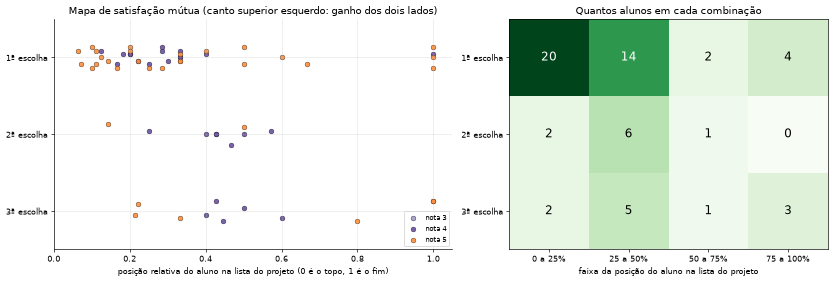

In [39]:
def resumosatisfacao(I, par):
    ordem = np.array([I.escolha[a][p] for a, p in par.items()])
    pos = np.array([I.pos[p][a] for a, p in par.items()])
    rel = np.array([I.pos[p][a] / len(I.lista[p]) for a, p in par.items()])
    return pd.DataFrame({
        'Medida': ['Alunos alocados',
                   'Lado do aluno: ordem de escolha média (1 é a melhor)',
                   'Lado do aluno: alocados na 1ª escolha (%)',
                   'Lado do aluno: alocados na 1ª ou 2ª escolha (%)',
                   'Lado do projeto: posição média do aluno na lista do projeto',
                   'Lado do projeto: posição relativa média (0 é o topo, 1 é o fim)',
                   'Lado do projeto: alunos que eram o 1º da lista do projeto (%)'],
        'Valor': [len(par), round(float(ordem.mean()), 2), round(100 * float((ordem == 1).mean()), 1),
                  round(100 * float((ordem <= 2).mean()), 1), round(float(pos.mean()), 2),
                  round(float(rel.mean()), 3), round(100 * float((pos == 1).mean()), 1)]})


def desenharganhoperda(I, par):
    alunosm = sorted(par)
    rel = np.array([I.pos[par[a]][a] / len(I.lista[par[a]]) for a in alunosm])
    ordem = np.array([I.escolha[a][par[a]] for a in alunosm])
    notas = np.array([I.nota[a] for a in alunosm])
    desloc = np.array([((i % 7) - 3) * 0.045 for i in range(len(alunosm))])   # fixo, sem sorteio
    fig, axs = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={'width_ratios': [1.25, 1]})
    ax = axs[0]
    for nota, cor in ((3, '#9e9ac8'), (4, '#6a51a3'), (5, '#fd8d3c')):
        m = notas == nota
        ax.scatter(rel[m], ordem[m] + desloc[m], s=34, color=cor, edgecolors='black', linewidths=0.4,
                   label=f'nota {nota}', alpha=0.9)
    ax.set_xlim(0, 1.05)
    ax.set_ylim(3.5, 0.5)
    ax.set_yticks([1, 2, 3])
    ax.set_yticklabels(['1ª escolha', '2ª escolha', '3ª escolha'])
    ax.set_xlabel('posição relativa do aluno na lista do projeto (0 é o topo, 1 é o fim)')
    ax.set_title('Mapa de satisfação mútua (canto superior esquerdo: ganho dos dois lados)')
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8, loc='lower right')
    ax.spines[['top', 'right']].set_visible(False)
    faixa = np.minimum((rel * 4 - 1e-9).astype(int), 3)
    M = np.zeros((3, 4), dtype=int)
    for o, f in zip(ordem, faixa):
        M[o - 1, f] += 1
    ax = axs[1]
    ax.imshow(M, cmap='Greens', aspect='auto')
    for i in range(3):
        for j in range(4):
            ax.text(j, i, M[i, j], ha='center', va='center', fontsize=14,
                    color='white' if M[i, j] > M.max() * 0.6 else 'black')
    ax.set_xticks(range(4))
    ax.set_xticklabels(['0 a 25%', '25 a 50%', '50 a 75%', '75 a 100%'])
    ax.set_yticks(range(3))
    ax.set_yticklabels(['1ª escolha', '2ª escolha', '3ª escolha'])
    ax.set_xlabel('faixa da posição do aluno na lista do projeto')
    ax.set_title('Quantos alunos em cada combinação')
    plt.tight_layout()
    salvarfigura(fig, 'ganho-perda')
    plt.show()


display(resumosatisfacao(I, parfinal).style.hide(axis='index'))
if MOSTRARGRAFICOS:
    desenharganhoperda(I, parfinal)

### **Etapa 9c.** Exportação dos resultados

Grava as tabelas desta execução em `resultados/`: a matriz final, o índice de preferência, as ocorrências da limpeza, a evolução das duas simulações e a comparação entre as versões. O arquivo `parametros.json` registra os parâmetros, as versões das bibliotecas e a impressão digital (SHA-256) do arquivo de entrada, e não contém datas nem tempos, então duas execuções geram arquivos idênticos. No fim, a célula lista o que foi gravado. No Google Colab ela também baixa um zip com tudo, porque o disco da sessão é apagado quando ela termina.

In [40]:
import hashlib
import json

if SALVARSAIDAS:
    salvartabela(dfmatriz, 'matriz-final')
    salvartabela(dfindice.sort_values('Índice de preferência', ascending=False).reset_index(drop=True), 'indice-preferencia')
    salvartabela(dfocorrencias, 'ocorrencias-limpeza')
    salvartabela(tabelaevolucao(resaluno), 'evolucao-aluno-propoe')
    salvartabela(tabelaevolucao(resprojeto), 'evolucao-projeto-propoe')
    salvartabela(dfcomp.rename_axis('Momento').reset_index(), 'comparacao-versoes')
    meta = {
        'parametros': {'NITERACOES': NITERACOES, 'DESEMPATE': DESEMPATE, 'MAXPASSOSCAMINHO': MAXPASSOSCAMINHO},
        'entrada_sha256': hashlib.sha256(open(ARQUIVO, 'rb').read()).hexdigest(),
        'versoes': {'python': platform.python_version(), 'numpy': np.__version__,
                    'pandas': pd.__version__, 'matplotlib': matplotlib.__version__},
        'resultado': {'alunos_alocados': len(parfinal), 'projetos_com_aluno': len(set(parfinal.values())),
                      'primeira_escolha': int(ordens[1]), 'segunda_escolha': int(ordens[2]),
                      'terceira_escolha': int(ordens[3])}}
    with open(os.path.join(PASTARESULTADOS, 'parametros.json'), 'w', encoding='utf-8') as f:
        json.dump(meta, f, ensure_ascii=False, indent=2)
        f.write('\n')
    print('Arquivos gravados:')
    for pasta in (PASTAFIGURAS, PASTARESULTADOS):
        if not os.path.isdir(pasta):              # sem figuras quando MOSTRARGRAFICOS = False
            continue
        for nome in sorted(os.listdir(pasta)):
            print(f'  {os.path.normpath(os.path.join(pasta, nome)):<55} {os.path.getsize(os.path.join(pasta, nome)) / 1024:8.0f} KB')
    try:                                          # só no Colab: baixa tudo de uma vez
        from google.colab import files
        import zipfile
        with zipfile.ZipFile('projeto2-saidas.zip', 'w', zipfile.ZIP_DEFLATED) as z:
            for pasta in (PASTAFIGURAS, PASTARESULTADOS):
                for raiz, _, nomes in os.walk(pasta):
                    for nome in nomes:
                        z.write(os.path.join(raiz, nome))
        files.download('projeto2-saidas.zip')
    except ImportError:
        pass
else:
    print('SALVARSAIDAS = False: nada foi gravado.')

Arquivos gravados:
  ..\figuras\alocacao-final.png                                253 KB
  ..\figuras\aluno-propoe-iteracao-01.png                      391 KB
  ..\figuras\aluno-propoe-iteracao-02.png                      427 KB
  ..\figuras\aluno-propoe-iteracao-03.png                      414 KB
  ..\figuras\aluno-propoe-iteracao-04.png                      417 KB
  ..\figuras\aluno-propoe-iteracao-05.png                      417 KB
  ..\figuras\aluno-propoe-iteracao-06.png                      419 KB
  ..\figuras\aluno-propoe-iteracao-07.png                      420 KB
  ..\figuras\aluno-propoe-iteracao-08.png                      425 KB
  ..\figuras\aluno-propoe-iteracao-09.png                      425 KB
  ..\figuras\aluno-propoe-iteracao-10.png                      425 KB
  ..\figuras\demanda-vagas.png                                  16 KB
  ..\figuras\evolucao-aluno-propoe.gif                         719 KB
  ..\figuras\evolucao-projeto-propoe.gif                       482 KB
 

## **Etapa 10.** Quem ficou de fora e quais projetos foram realizados

Esta etapa responde a duas perguntas do enunciado: quais projetos foram realizados e quem ficou de fora. Um projeto é realizado quando termina com pelo menos um aluno.

`analisarprojetos` mostra a situação de cada projeto. Um projeto sem aluno é marcado como não realizado e o motivo é um de dois: ninguém qualificado o escolheu (os interessados foram barrados pela nota mínima ou ninguém o colocou na lista), ou os candidatos qualificados existiam, mas todos acabaram em projetos que preferem a ele. Quando um projeto realizado fica com vaga sobrando, o motivo é o mesmo.

`analisaralunosfora` explica cada aluno sem projeto. Há dois grupos. O primeiro não tem nenhuma opção elegível, ou porque a nota barra todos os projetos da sua lista ou porque só citou projetos que não existem, e por isso nunca entrou no grafo. O segundo tem opção elegível, mas ficou sem vaga: em uma alocação estável isso só acontece se cada projeto elegível dele estiver cheio com alunos de nota maior ou igual à dele (se houvesse vaga livre, ou um aluno de nota menor, o par seria bloqueante). A coluna `Justificado` confere isso aluno por aluno.

Projetos realizados: 41 de 50   Projetos não realizados: 9
Vagas preenchidas: 60 de 80   Projetos realizados com vaga sobrando: 3

Projetos não realizados e o motivo:


,Projeto,Vagas,Qualificados,Barrados pela nota,Categoria,Motivo
0,P11,2,0,5,sem candidato qualificado,"5 interessado(s), todos barrados pela nota mínima 5"
1,P13,2,0,5,sem candidato qualificado,"5 interessado(s), todos barrados pela nota mínima 5"
2,P19,2,0,19,sem candidato qualificado,"19 interessado(s), todos barrados pela nota mínima 5"
3,P23,1,1,3,candidatos preferiram outro projeto,"1 candidato(s) qualificado(s), todos alocados em projeto que preferem a P23"
4,P32,2,0,5,sem candidato qualificado,"5 interessado(s), todos barrados pela nota mínima 5"
5,P33,2,0,5,sem candidato qualificado,"5 interessado(s), todos barrados pela nota mínima 5"
6,P42,2,0,4,sem candidato qualificado,"4 interessado(s), todos barrados pela nota mínima 5"
7,P44,2,1,2,candidatos preferiram outro projeto,"1 candidato(s) qualificado(s), todos alocados em projeto que preferem a P44"
8,P46,2,0,3,sem candidato qualificado,"3 interessado(s), todos barrados pela nota mínima 5"


Vagas ocupadas por projeto:


,Projeto,Vagas,Alunos alocados,Situação,Vagas livres
0,P1,2,2,Realizado,0
1,P2,2,2,Realizado,0
2,P3,2,2,Realizado,0
3,P4,1,1,Realizado,0
4,P5,2,2,Realizado,0
5,P6,2,1,Realizado,1
6,P7,2,2,Realizado,0
7,P8,2,2,Realizado,0
8,P9,2,2,Realizado,0
9,P10,2,2,Realizado,0


Projetos realizados que ficaram com vaga sobrando:


,Projeto,Vagas,Alunos alocados,Qualificados,Motivo
0,P6,2,1,1,1 vaga(s) livre(s): todos os 1 candidato(s) qualificado(s) já estão alocados aqui
1,P31,2,1,2,1 vaga(s) livre(s): os outros 1 candidato(s) qualificado(s) estão em projetos que pref...
2,P50,2,1,1,1 vaga(s) livre(s): todos os 1 candidato(s) qualificado(s) já estão alocados aqui


Alunos sem projeto: 140 de 200
Categoria
com opção elegível, sem vaga                    74
sem opção elegível: todas barradas pela nota    66

Alunos com opção elegível que ficaram sem vaga (cada opção está cheia com alunos de nota maior ou igual):


,Aluno,Nota,Projetos elegíveis,Detalhe,Justificado
0,A4,4,"P3, P5","P3 cheio (notas [5, 5]); P5 cheio (notas [5, 5])",True
1,A5,3,P28,P28 cheio (notas [5]),True
2,A7,4,P41,"P41 cheio (notas [5, 5])",True
3,A17,4,"P21, P18","P21 cheio (notas [5]); P18 cheio (notas [5, 5])",True
4,A21,3,P17,P17 cheio (notas [4]),True
5,A22,4,P18,"P18 cheio (notas [5, 5])",True
6,A25,4,P34,P34 cheio (notas [4]),True
7,A26,4,"P40, P9, P15","P40 cheio (notas [5]); P9 cheio (notas [4, 4]); P15 cheio (notas [4, 4])",True
8,A27,4,P41,"P41 cheio (notas [5, 5])",True
9,A38,3,P28,P28 cheio (notas [5]),True


Alunos sem nenhuma opção elegível (nunca puderam entrar no grafo):


,Aluno,Nota,Categoria,Detalhe
0,A3,3,sem opção elegível: todas barradas pela nota,P30 exige 4; P34 exige 4; P35 exige 4
1,A9,3,sem opção elegível: todas barradas pela nota,P7 exige 5; P29 exige 4; P9 exige 4
2,A12,3,sem opção elegível: todas barradas pela nota,P2 exige 5; P20 exige 4; P4 exige 5
3,A13,3,sem opção elegível: todas barradas pela nota,P3 exige 4; P30 exige 4; P45 exige 4
4,A15,3,sem opção elegível: todas barradas pela nota,P5 exige 4; P48 exige 5; P24 exige 4
5,A16,4,sem opção elegível: todas barradas pela nota,P6 exige 5; P19 exige 5
6,A19,3,sem opção elegível: todas barradas pela nota,P9 exige 4; P19 exige 5; P49 exige 4
7,A20,3,sem opção elegível: todas barradas pela nota,P10 exige 4; P34 exige 4; P5 exige 4
8,A28,3,sem opção elegível: todas barradas pela nota,P6 exige 5; P27 exige 5; P8 exige 5
9,A29,3,sem opção elegível: todas barradas pela nota,P7 exige 5; P29 exige 4; P9 exige 4


Conferência: 60 alocados + 140 de fora = 200 alunos; 41 realizados + 9 não realizados = 50 projetos
Todo aluno de fora tem justificativa (projetos cheios com notas maiores ou iguais)? True


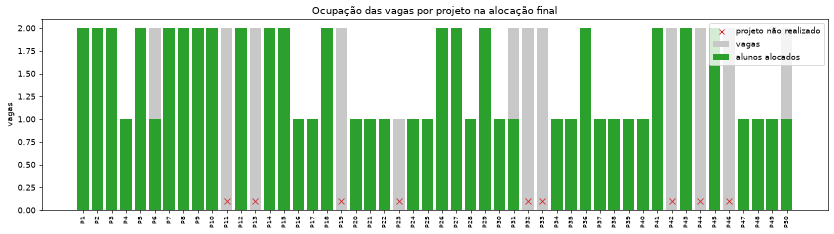

In [41]:
def analisarprojetos(I, par):
    """Situação de cada projeto: realizado (pelo menos 1 aluno) ou não realizado, com o motivo."""
    ocup = ocupantes(par)
    linhas = []
    for p in sorted(I.projetos):
        n, vagas = len(ocup[p]), I.vagas[p]
        qualificados = I.cand[p]
        interessados = [a for a in I.alunos if p in I.alunos[a]['validastodas']]
        barrados = len(interessados) - len(qualificados)
        # candidatos qualificados que não estão neste projeto: todos têm de estar em um projeto que preferem
        # (se não estivessem, o par (aluno, projeto) bloquearia a alocação)
        outros = [a for a in qualificados if par.get(a) != p]
        if n == 0 and not qualificados:
            situacao, categoria = 'Não realizado', 'sem candidato qualificado'
            motivo = (f'{barrados} interessado(s), todos barrados pela nota mínima {I.req[p]}'
                      if barrados else 'nenhum aluno colocou o projeto na lista')
        elif n == 0:
            situacao, categoria = 'Não realizado', 'candidatos preferiram outro projeto'
            motivo = f'{len(qualificados)} candidato(s) qualificado(s), todos alocados em projeto que preferem a P{p}'
        else:
            situacao, categoria = 'Realizado', ''
            if n < vagas and not outros:
                motivo = f'{vagas - n} vaga(s) livre(s): todos os {len(qualificados)} candidato(s) qualificado(s) já estão alocados aqui'
            elif n < vagas:
                motivo = (f'{vagas - n} vaga(s) livre(s): os outros {len(outros)} candidato(s) qualificado(s) '
                          f'estão em projetos que preferem a P{p}')
            else:
                motivo = ''
        linhas.append({'Projeto': f'P{p}', 'Vagas': vagas, 'Alunos alocados': n, 'Situação': situacao,
                       'Qualificados': len(qualificados), 'Barrados pela nota': barrados,
                       'Categoria': categoria, 'Motivo': motivo})
    return pd.DataFrame(linhas)


def analisaralunosfora(I, par):
    """Motivo de cada aluno sem projeto. Aluno com opção elegível só fica de fora se todos
    os projetos que ele pode ocupar estão cheios com alunos de nota maior ou igual à dele."""
    ocup = ocupantes(par)
    linhas = []
    for a in sorted(I.alunos):
        if a in par:
            continue
        d = I.alunos[a]
        if d['prefs']:
            categoria = 'com opção elegível, sem vaga'
            partes, justificado = [], True
            for p in d['prefs']:
                notas = sorted((I.nota[x] for x in ocup[p]), reverse=True)
                cheio = len(ocup[p]) >= I.vagas[p] and min(notas) >= I.nota[a]
                justificado = justificado and cheio
                partes.append(f'P{p} cheio (notas {notas})')
            detalhe = '; '.join(partes)
        else:
            justificado = True
            if d['validastodas']:
                categoria = 'sem opção elegível: todas barradas pela nota'
                detalhe = '; '.join(f"P{p} exige {I.req[p]}" for p in d['barradas'])
            else:
                categoria = 'sem opção válida na lista'
                detalhe = 'só projetos inexistentes'
        linhas.append({'Aluno': f'A{a}', 'Nota': d['nota'], 'Categoria': categoria,
                       'Projetos elegíveis': ', '.join(f'P{p}' for p in d['prefs']) or '-',
                       'Detalhe': detalhe, 'Justificado': justificado})
    return pd.DataFrame(linhas, columns=['Aluno', 'Nota', 'Categoria', 'Projetos elegíveis', 'Detalhe', 'Justificado'])


dfprojetos = analisarprojetos(I, parfinal)
dffora = analisaralunosfora(I, parfinal)

realizados = dfprojetos[dfprojetos['Situação'] == 'Realizado']
naorealizados = dfprojetos[dfprojetos['Situação'] != 'Realizado']
print(f"Projetos realizados: {len(realizados)} de {len(dfprojetos)}   Projetos não realizados: {len(naorealizados)}")
print(f"Vagas preenchidas: {len(parfinal)} de {sum(I.vagas.values())}   "
      f"Projetos realizados com vaga sobrando: {(realizados['Alunos alocados'] < realizados['Vagas']).sum()}")
print()
print('Projetos não realizados e o motivo:')
display(naorealizados[['Projeto', 'Vagas', 'Qualificados', 'Barrados pela nota', 'Categoria', 'Motivo']].reset_index(drop=True))
print('Vagas ocupadas por projeto:')
display(dfprojetos[['Projeto', 'Vagas', 'Alunos alocados', 'Situação']].assign(**{'Vagas livres': dfprojetos['Vagas'] - dfprojetos['Alunos alocados']}).reset_index(drop=True))
print('Projetos realizados que ficaram com vaga sobrando:')
display(realizados[realizados['Alunos alocados'] < realizados['Vagas']][['Projeto', 'Vagas', 'Alunos alocados', 'Qualificados', 'Motivo']].reset_index(drop=True))

print(f"Alunos sem projeto: {len(dffora)} de {len(I.alunos)}")
print(dffora['Categoria'].value_counts().to_string())
print()
print('Alunos com opção elegível que ficaram sem vaga (cada opção está cheia com alunos de nota maior ou igual):')
display(dffora[dffora['Categoria'] == 'com opção elegível, sem vaga'].drop(columns=['Categoria']).reset_index(drop=True))
print('Alunos sem nenhuma opção elegível (nunca puderam entrar no grafo):')
display(dffora[dffora['Categoria'] != 'com opção elegível, sem vaga'].drop(columns=['Projetos elegíveis', 'Justificado']).reset_index(drop=True))
# conferência de contagem
assert len(parfinal) + len(dffora) == len(I.alunos), 'alunos alocados + alunos de fora têm de somar o total de alunos'
assert len(realizados) + len(naorealizados) == len(I.projetos), 'projetos realizados + não realizados têm de somar o total de projetos'
print(f"Conferência: {len(parfinal)} alocados + {len(dffora)} de fora = {len(parfinal) + len(dffora)} alunos; "
      f"{len(realizados)} realizados + {len(naorealizados)} não realizados = {len(realizados) + len(naorealizados)} projetos")
print('Todo aluno de fora tem justificativa (projetos cheios com notas maiores ou iguais)?', bool(dffora['Justificado'].all()))

if MOSTRARGRAFICOS:
    ps = sorted(I.projetos)
    ocupf = Counter(parfinal.values())
    fig, ax = plt.subplots(figsize=(14, 4))
    ax.bar([f'P{p}' for p in ps], [I.vagas[p] for p in ps], color=CORFUNDO, label='vagas')
    ax.bar([f'P{p}' for p in ps], [ocupf[p] for p in ps], color=CORTEMPORARIO, label='alunos alocados')
    for i, p in enumerate(ps):
        if ocupf[p] == 0:
            ax.plot(i, 0.1, marker='x', color=CORREJEICAO, markersize=7)
    ax.plot([], [], marker='x', color=CORREJEICAO, ls='', label='projeto não realizado')
    ax.set_title('Ocupação das vagas por projeto na alocação final')
    ax.set_ylabel('vagas')
    ax.legend()
    plt.xticks(rotation=90, fontsize=7)
    plt.tight_layout()
    plt.show()

## **Etapa 11.** Quão bom é o resultado: limite superior e prova de otimalidade

O enunciado pede o máximo de alunos alocados, então precisamos saber o quanto o resultado está longe do melhor possível. Esta etapa tem quatro partes.

1. **Limites superiores.** Nenhuma alocação aloca mais que as vagas totais, nem mais que os alunos com opção elegível. Um limite melhor é o maior emparelhamento possível sem exigir estabilidade, calculado de duas formas independentes (caminhos aumentantes com capacidades e fluxo máximo) que têm de dar o mesmo número. O mesmo cálculo com uma vaga por projeto limita quantos projetos podem ter aluno.
2. **Prova de otimalidade.** Com empates de nota, achar o maior emparelhamento estável é um problema difícil, então o laço não garante o ótimo. Para verificar, `otimoestavel` resolve o problema exatamente por programação inteira. Há uma variável por aresta elegível, e a restrição de estabilidade diz que, se o aluno a não está em p nem em algo que prefere a p, então p está cheio só com alunos de nota maior ou igual à de a. Isso é exatamente a estabilidade fraca usada na etapa 8. Maximizamos o número de alunos e, em seguida, com esse tamanho fixado, o número de projetos realizados. Se o valor do laço for igual ao ótimo, está provado que nenhuma alocação estável é melhor.
3. **Teorema dos hospitais rurais.** Com listas estritas, todas as alocações estáveis emparelham os mesmos alunos e o mesmo número de alunos por projeto. Conferimos isso no fim da fase 1 das duas versões. Os alunos que a fase 2 acrescenta só existem por causa dos empates de nota.
4. **Sensibilidade ao desempate.** Repetimos o laço do lado do projeto com as três regras de desempate. O ótimo estável não muda, porque a estabilidade fraca só olha a nota, então dá para ver se cada regra chega até ele.

Limites superiores para o número de alunos alocados:
  vagas totais:                                     80
  alunos com pelo menos uma opção elegível:         134
  maior emparelhamento sem exigir estabilidade:     63 (caminhos aumentantes) e 63 (fluxo máximo)
Limite superior para o número de projetos realizados (sem exigir estabilidade): 43

Maior emparelhamento fracamente estável (programação inteira): 60 alunos (ótimo comprovado), 0.1 s
Alocação final do laço: 60 alunos
Diferença para o ótimo estável: 0
Custo da estabilidade (sem estabilidade - com estabilidade): 3 aluno(s)
Solução exata respeita vagas: True, só projetos da lista: True, pares bloqueantes fracos: 0
Entre os emparelhamentos estáveis de tamanho 60, o máximo de projetos realizados é 41 (ótimo comprovado); a alocação final realiza 41

Fim da fase 1: mesmo conjunto de alunos emparelhados nas duas versões? True; mesma ocupação por projeto? True
Todo emparelhamento estável estrito (com o desempate 'escolha') tem 57 alunos;

,Desempate,Alunos no fim da fase 1,Alunos no fim do laço,Projetos com aluno,1ª escolha,2ª escolha,3ª escolha,Pares bloqueantes fracos,Distância ao ótimo estável
0,escolha,57,60,41,40,9,11,0,0
1,escassez,57,60,41,36,9,15,0,0
2,codigo,57,60,41,36,10,14,0,0


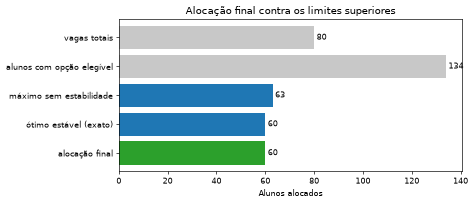

In [42]:
from scipy.optimize import milp, LinearConstraint, Bounds
from scipy.sparse import lil_matrix, csr_matrix
from scipy.sparse.csgraph import maximum_flow


def fluxomaximo(I, capacidade=None):
    """Maior emparelhamento sem exigir estabilidade, calculado por fluxo máximo
    (fonte -> alunos -> projetos -> sumidouro). Confere o algoritmo de caminhos aumentantes."""
    capacidade = capacidade or I.vagas
    alun = I.elegiveis
    idxa = {a: 1 + i for i, a in enumerate(alun)}
    idxp = {p: 1 + len(alun) + j for j, p in enumerate(sorted(I.projetos))}
    n = 2 + len(alun) + len(I.projetos)
    M = lil_matrix((n, n), dtype=np.int32)
    for a in alun:
        M[0, idxa[a]] = 1
        for p in I.prefs[a]:
            M[idxa[a], idxp[p]] = 1
    for p in I.projetos:
        M[idxp[p], n - 1] = capacidade[p]
    return int(maximum_flow(csr_matrix(M), 0, n - 1).flow_value)


def otimoestavel(I, fixartam=None, maisprojetos=False, limite=120):
    """Programação inteira exata: maior emparelhamento fracamente estável.
    x[a,p] = 1 se o aluno a é alocado em p. Restrições:
      - cada aluno em no máximo um projeto e cada projeto em no máximo suas vagas;
      - para cada aresta (a, p): se a não está em p nem em um projeto que prefere a p, então
        p está cheio só com alunos de nota maior ou igual à de a (senão (a, p) bloquearia).
    Com maisprojetos=True, fixa o tamanho em 'fixartam' e maximiza os projetos com pelo menos um aluno."""
    arestas = [(a, p) for a in I.elegiveis for p in I.prefs[a]]
    idx = {e: i for i, e in enumerate(arestas)}
    ps = sorted(I.projetos)
    nx = len(arestas)
    ny = len(ps) if maisprojetos else 0
    yidx = {p: nx + j for j, p in enumerate(ps)}
    linhas, lo, hi = [], [], []

    def nova(coefs, inf, sup):
        linhas.append(coefs); lo.append(inf); hi.append(sup)

    for a in I.elegiveis:
        nova({idx[(a, p)]: 1 for p in I.prefs[a]}, 0, 1)
    for p in ps:
        nova({idx[(a, p)]: 1 for a in I.cand[p]}, 0, I.vagas[p])
    for a, p in arestas:
        c = defaultdict(float)
        for q in I.prefs[a]:
            if I.escolha[a][q] <= I.escolha[a][p]:       # p ou algo que a prefere a p
                c[idx[(a, q)]] += I.vagas[p]
        for b in I.cand[p]:
            if I.nota[b] >= I.nota[a]:                    # alunos que p não prefere estritamente a b
                c[idx[(b, p)]] += 1
        nova(c, I.vagas[p], np.inf)
    if maisprojetos:
        nova({i: 1 for i in range(nx)}, fixartam, fixartam)
        for p in ps:                                      # y[p] = 1 só se p tem algum aluno
            c = {idx[(a, p)]: -1 for a in I.cand[p]}
            c[yidx[p]] = 1
            nova(c, -np.inf, 0)
    A = lil_matrix((len(linhas), nx + ny))
    for i, c in enumerate(linhas):
        for j, v in c.items():
            A[i, j] = v
    obj = np.zeros(nx + ny)
    obj[nx:] = -1 if maisprojetos else 0
    if not maisprojetos:
        obj[:nx] = -1
    res = milp(obj, constraints=LinearConstraint(csr_matrix(A), lo, hi), integrality=np.ones(nx + ny),
               bounds=Bounds(0, 1), options={'time_limit': limite})
    if res.x is None:
        return None
    par = {a: p for (a, p), i in idx.items() if res.x[i] > 0.5}
    return {'par': par, 'otimo': res.status == 0, 'valor': int(round(-res.fun)),
            'limitesup': int(math.floor(-getattr(res, 'mip_dual_bound', res.fun) + 1e-6))}


# 1. limites superiores
semestab = maxcardinalidade(I)
fluxo = fluxomaximo(I)
semestabproj = fluxomaximo(I, {p: 1 for p in I.projetos})
print('Limites superiores para o número de alunos alocados:')
print(f"  vagas totais:                                     {sum(I.vagas.values())}")
print(f"  alunos com pelo menos uma opção elegível:         {len(I.elegiveis)}")
print(f"  maior emparelhamento sem exigir estabilidade:     {len(semestab)} (caminhos aumentantes) e {fluxo} (fluxo máximo)")
assert len(semestab) == fluxo, 'os dois métodos têm de coincidir'
print(f"Limite superior para o número de projetos realizados (sem exigir estabilidade): {semestabproj}")
print()

# 2. otimalidade entre os emparelhamentos estáveis, por programação inteira exata
t0 = time.time()
exato = otimoestavel(I)
tempo = time.time() - t0
print(f"Maior emparelhamento fracamente estável (programação inteira): {exato['valor']} alunos "
      f"({'ótimo comprovado' if exato['otimo'] else 'limite de tempo, limite superior ' + str(exato['limitesup'])}), {tempo:.1f} s")
print(f"Alocação final do laço: {len(parfinal)} alunos")
print(f"Diferença para o ótimo estável: {exato['valor'] - len(parfinal)}")
print(f"Custo da estabilidade (sem estabilidade - com estabilidade): {len(semestab) - exato['valor']} aluno(s)")
chk = verificar(I, exato['par'])
print(f"Solução exata respeita vagas: {chk['respeita vagas']}, só projetos da lista: {chk['só projetos da lista']}, "
      f"pares bloqueantes fracos: {chk['pares bloqueantes fracos']}")
assert chk['pares bloqueantes fracos'] == 0

exato2 = otimoestavel(I, fixartam=exato['valor'], maisprojetos=True)
projfinal = len(set(parfinal.values()))
print(f"Entre os emparelhamentos estáveis de tamanho {exato['valor']}, o máximo de projetos realizados é {exato2['valor']} "
      f"({'ótimo comprovado' if exato2['otimo'] else 'limite de tempo'}); a alocação final realiza {projfinal}")
print()

# 3. teorema dos hospitais rurais: no fim da fase 1 os dois sentidos têm os mesmos alunos e o mesmo número por projeto
mesmosalunos = set(resaluno['parda']) == set(resprojeto['parda'])
mesmaocup = Counter(resaluno['parda'].values()) == Counter(resprojeto['parda'].values())
print(f"Fim da fase 1: mesmo conjunto de alunos emparelhados nas duas versões? {mesmosalunos}; mesma ocupação por projeto? {mesmaocup}")
print(f"Todo emparelhamento estável estrito (com o desempate '{DESEMPATE}') tem {len(resprojeto['parda'])} alunos; "
      f"os {len(parfinal) - len(resprojeto['parda'])} alunos a mais do laço vêm da fase 2, que usa os empates de nota.")
print()

# 4. sensibilidade ao desempate: o ótimo não muda (a estabilidade fraca só usa a nota), o laço pode mudar
linhas = []
for regra in ('escolha', 'escassez', 'codigo'):
    Ir = Instancia(projetos, alunos, regra)
    r = simular(Ir, 'projeto')
    ords = Counter(Ir.escolha[a][p] for a, p in r['par'].items())
    linhas.append({'Desempate': regra, 'Alunos no fim da fase 1': r['tamda'] if r['tamda'] is not None else '-',
                   'Alunos no fim do laço': len(r['par']), 'Projetos com aluno': len(set(r['par'].values())),
                   '1ª escolha': ords[1], '2ª escolha': ords[2], '3ª escolha': ords[3],
                   'Pares bloqueantes fracos': len(paresbloqueantes(Ir, r['par'], fraca=True)),
                   'Distância ao ótimo estável': exato['valor'] - len(r['par'])})
dfsens = pd.DataFrame(linhas)
display(dfsens)

if MOSTRARGRAFICOS:
    rotulos = ['vagas totais', 'alunos com opção elegível', 'máximo sem estabilidade', 'ótimo estável (exato)', 'alocação final']
    valores = [sum(I.vagas.values()), len(I.elegiveis), len(semestab), exato['valor'], len(parfinal)]
    fig, ax = plt.subplots(figsize=(8, 3.5))
    barras = ax.barh(rotulos[::-1], valores[::-1], color=[CORTEMPORARIO, CORPROPOSTA, CORPROPOSTA, CORFUNDO, CORFUNDO])
    ax.bar_label(barras, padding=3)
    ax.set_xlabel('Alunos alocados')
    ax.set_title('Alocação final contra os limites superiores')
    plt.tight_layout()
    plt.show()

## Conclusões



In [43]:
from IPython.display import Markdown

# números que aparecem no texto, todos calculados nas etapas anteriores
hist = resprojeto['historico']
nfinal, vagastot = len(parfinal), sum(I.vagas.values())
projfinal = len(set(parfinal.values()))
tamfase1 = resprojeto['tamda'] if resprojeto['tamda'] is not None else nfinal
itfase1 = max((r['t'] for r in hist if r['props']), default=0)
caminhos = [(r['t'], len(r['fase2']['caminho'])) for r in hist if r['fase2'] and r['fase2']['caminho']]
itultimo = max((t for t, _ in caminhos), default=itfase1)
npropostas = sum(len(r['props']) for r in hist)
nrejeicoes = sum(len(r['rejs']) for r in hist)
estritos = len(paresbloqueantes(I, parfinal, fraca=False))
blqfase1 = len(paresbloqueantes(I, resprojeto['parda'], fraca=False)) if resprojeto['parda'] is not None else 0
fracos = len(paresbloqueantes(I, parfinal, fraca=True))
nsemelegivel = int((dffora['Categoria'] != 'com opção elegível, sem vaga').sum())
nsemvaga = int((dffora['Categoria'] == 'com opção elegível, sem vaga').sum())
nsemcand = int((naorealizados['Categoria'] == 'sem candidato qualificado').sum())
nprefoutro = int((naorealizados['Categoria'] == 'candidatos preferiram outro projeto').sum())
tams = dict(zip(dfsens['Desempate'], dfsens['Alunos no fim do laço']))
v, ub = exato['valor'], len(semestab)

if exato['otimo'] and nfinal == v:
    otimo = (f"A alocação final tem {nfinal} alunos, e a programação inteira exata mostra que {v} é o maior número possível "
             f"de alunos em uma alocação estável. Ou seja, o laço chegou ao ótimo e nenhuma alocação estável aloca mais gente. "
             f"Sem a exigência de estabilidade seria possível alocar até {ub} alunos, então a estabilidade custa {ub - v} aluno(s).")
elif exato['otimo']:
    otimo = (f"A alocação final tem {nfinal} alunos, mas a programação inteira exata encontrou uma alocação estável com {v}. "
             f"O laço ficou {v - nfinal} aluno(s) abaixo do ótimo, por causa do limite de iterações e do comprimento máximo do caminho aumentante. "
             f"Sem a exigência de estabilidade seria possível alocar até {ub} alunos.")
else:
    otimo = (f"A alocação final tem {nfinal} alunos. A programação inteira não terminou dentro do limite de tempo e garante só que "
             f"nenhuma alocação estável passa de {exato['limitesup']}. Sem a exigência de estabilidade o limite é {ub}.")
if exato2 is not None and exato2['otimo']:
    otimoproj = (f"O mesmo vale para os projetos: entre as alocações estáveis com {v} alunos, o máximo de projetos realizados é {exato2['valor']}, "
                 + (f"e a alocação final realiza {projfinal}." if projfinal == exato2['valor']
                    else f"mas a alocação final realiza {projfinal}."))
else:
    otimoproj = f"A alocação final realiza {projfinal} projetos."

if len(set(tams.values())) == 1:
    sens = (f"As três regras de desempate terminam com o mesmo número de alunos alocados ({nfinal}); muda só quem ocupa as vagas, "
            f"e portanto a ordem de escolha obtida e a posição dos alunos na lista dos projetos.")
else:
    sens = ('O número de alunos alocados no fim do laço depende da regra de desempate: '
            + ', '.join(f"{r} {t}" for r, t in tams.items()) + f". O ótimo estável ({v}) não depende da regra, porque a estabilidade fraca só usa a nota.")

texto = [
 f"**Resultado:** a proposta final (projeto propõe, seguida da fase 2) aloca **{nfinal} dos {len(I.alunos)} alunos em {projfinal} dos {len(I.projetos)} projetos**, "
 f"ocupando {nfinal} das {vagastot} vagas. Por ordem de escolha do aluno, {ordens[1]} ficaram com a 1ª opção, {ordens[2]} com a 2ª e {ordens[3]} com a 3ª, "
 f"então {100 * ordens[1] / nfinal:.0f}% dos alocados conseguiram o projeto que mais queriam. Ficaram de fora {len(dffora)} alunos: {nsemelegivel} não tinham nenhuma opção elegível "
 f"(todas barradas pela nota mínima ou inexistentes) e {nsemvaga} tinham opção, mas todos os seus projetos já estavam cheios com alunos de nota maior ou igual. "
 f"Dos projetos, {len(naorealizados)} não foram realizados: {nsemcand} sem nenhum candidato qualificado e {nprefoutro} cujos candidatos qualificados preferiram outro projeto.",

 f"**Evolução do laço:** a fase 1 (aceitação adiada) trabalhou até a iteração {itfase1}, com {npropostas} propostas e {nrejeicoes} rejeições, e terminou com {tamfase1} alunos emparelhados, "
 f"uma alocação estável no sentido estrito. A fase 2 então acrescentou {nfinal - tamfase1} aluno(s) por caminhos alternados aumentantes"
 + (f" ({', '.join(f'{k} alunos na iteração {t}' for t, k in caminhos)})" if caminhos else '')
 + f", e o laço ficou estacionário depois da iteração {itultimo}.",

 f"**Quão bom é o resultado:** {otimo} {otimoproj} Os {len(dffora)} alunos de fora têm explicação individual na etapa 10: os que tinham opção elegível só ficaram sem vaga porque todos os seus projetos estavam cheios com alunos de nota maior ou igual.",

 f"**Estabilidade:** a alocação final tem {fracos} pares bloqueantes no sentido fraco, que é a definição fiel aos dados, e respeita as vagas e as listas dos alunos. "
 f"No sentido estrito sobram {estritos} pares, todos entre alunos de mesma nota em que o desempate escolhido por nós prefere um e o caminho aumentante levou o outro, "
 f"então eles não representam preferência real do projeto. No fim da fase 1 há {blqfase1} par(es) bloqueante(s) estrito(s). "
 f"As duas versões do algoritmo {'chegam exatamente à mesma alocação' if resaluno['par'] == resprojeto['par'] else 'chegam a alocações diferentes'}, "
 f"e no fim da fase 1 emparelham {'os mesmos alunos' if set(resaluno['parda']) == set(resprojeto['parda']) else 'alunos diferentes'}, "
 f"como prevê o teorema dos hospitais rurais (o conjunto de alunos emparelhados é o mesmo em toda alocação estável estrita).",

 f"**Sensibilidade ao desempate:** {sens}",

 "**o que falta:** o arquivo não traz a preferência dos projetos, então ela foi derivada da nota, com desempate determinístico, e todos os resultados valem para essa escolha. "
 "Se os professores tivessem uma lista própria, a lista estrita do Gale-Shapley seria a deles e os pares do desempate deixariam de ser arbitrários. "
 "Além disso, a fase 2 aceita só um caminho aumentante por iteração e olha caminhos de até `MAXPASSOSCAMINHO` alunos, então em instâncias maiores ela pode não alcançar o ótimo, "
 "e é por isso que a conferência exata da etapa 11 é útil.",
]
display(Markdown('\n\n'.join(texto)))

**Resultado:** a proposta final (projeto propõe, seguida da fase 2) aloca **60 dos 200 alunos em 41 dos 50 projetos**, ocupando 60 das 80 vagas. Por ordem de escolha do aluno, 40 ficaram com a 1ª opção, 9 com a 2ª e 11 com a 3ª, então 67% dos alocados conseguiram o projeto que mais queriam. Ficaram de fora 140 alunos: 66 não tinham nenhuma opção elegível (todas barradas pela nota mínima ou inexistentes) e 74 tinham opção, mas todos os seus projetos já estavam cheios com alunos de nota maior ou igual. Dos projetos, 9 não foram realizados: 7 sem nenhum candidato qualificado e 2 cujos candidatos qualificados preferiram outro projeto.

**Evolução do laço:** a fase 1 (aceitação adiada) trabalhou até a iteração 4, com 83 propostas e 26 rejeições, e terminou com 57 alunos emparelhados, uma alocação estável no sentido estrito. A fase 2 então acrescentou 3 aluno(s) por caminhos alternados aumentantes (2 alunos na iteração 5, 3 alunos na iteração 6, 4 alunos na iteração 7), e o laço ficou estacionário depois da iteração 7.

**Quão bom é o resultado:** A alocação final tem 60 alunos, e a programação inteira exata mostra que 60 é o maior número possível de alunos em uma alocação estável. Ou seja, o laço chegou ao ótimo e nenhuma alocação estável aloca mais gente. Sem a exigência de estabilidade seria possível alocar até 63 alunos, então a estabilidade custa 3 aluno(s). O mesmo vale para os projetos: entre as alocações estáveis com 60 alunos, o máximo de projetos realizados é 41, e a alocação final realiza 41. Os 140 alunos de fora têm explicação individual na etapa 10: os que tinham opção elegível só ficaram sem vaga porque todos os seus projetos estavam cheios com alunos de nota maior ou igual.

**Estabilidade:** a alocação final tem 0 pares bloqueantes no sentido fraco, que é a definição fiel aos dados, e respeita as vagas e as listas dos alunos. No sentido estrito sobram 4 pares, todos entre alunos de mesma nota em que o desempate escolhido por nós prefere um e o caminho aumentante levou o outro, então eles não representam preferência real do projeto. No fim da fase 1 há 0 par(es) bloqueante(s) estrito(s). As duas versões do algoritmo chegam exatamente à mesma alocação, e no fim da fase 1 emparelham os mesmos alunos, como prevê o teorema dos hospitais rurais (o conjunto de alunos emparelhados é o mesmo em toda alocação estável estrita).

**Sensibilidade ao desempate:** As três regras de desempate terminam com o mesmo número de alunos alocados (60); muda só quem ocupa as vagas, e portanto a ordem de escolha obtida e a posição dos alunos na lista dos projetos.

**o que falta:** o arquivo não traz a preferência dos projetos, então ela foi derivada da nota, com desempate determinístico, e todos os resultados valem para essa escolha. Se os professores tivessem uma lista própria, a lista estrita do Gale-Shapley seria a deles e os pares do desempate deixariam de ser arbitrários. Além disso, a fase 2 aceita só um caminho aumentante por iteração e olha caminhos de até `MAXPASSOSCAMINHO` alunos, então em instâncias maiores ela pode não alcançar o ótimo, e é por isso que a conferência exata da etapa 11 é útil.